In [181]:
!pip install miceforest

In [182]:
# ============================================
# 0. IMPORT LIBRARY
# ============================================
import numpy as np
import pandas as pd
import time

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import KNNImputer, IterativeImputer, SimpleImputer
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import BayesianRidge
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    matthews_corrcoef
)

RANDOM_STATE = 42
POS_LABEL = "triggered"
NEG_LABEL = "no_effect"

def compute_metrics(y_true, y_pred, y_proba=None, average='binary'):

    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average=average, pos_label=POS_LABEL),
        "Sensitivity": recall_score(y_true, y_pred, average=average, pos_label=POS_LABEL), # Sensitivity is another name for Recall
        "F1": f1_score(y_true, y_pred, average=average, pos_label=POS_LABEL)
    }

    # Calculate Specificity
    cm = confusion_matrix(y_true, y_pred, labels=[NEG_LABEL, POS_LABEL])
    TN, FP, FN, TP = cm.ravel()
    specificity = TN / (TN + FP) if (TN + FP) > 0 else 0
    metrics["Specificity"] = specificity

    # Calculate AUC if probabilities are available
    if y_proba is not None and hasattr(y_proba, 'shape') and y_proba.shape[1] > 1:
        # Binarize y_true to match the format expected by roc_auc_score for multiclass
        y_true_binarized = label_binarize(y_true, classes=[NEG_LABEL, POS_LABEL])
        # Use the probability of the positive class
        metrics["AUC"] = roc_auc_score(y_true_binarized, y_proba[:, 1])
    else:
        metrics["AUC"] = np.nan # Not applicable or probabilities not provided

    # Other metrics
    metrics["Error_Rate"] = 1 - metrics["Accuracy"]
    metrics["FPR"] = FP / (FP + TN) if (FP + TN) > 0 else 0
    metrics["FNR"] = FN / (FN + TP) if (FN + TP) > 0 else 0

    return metrics

In [183]:
import pandas as pd
from sklearn.model_selection import train_test_split # Added import

# ============================================
# 1. LOAD DATA & SPLIT TRAIN/TEST
# ============================================
data = pd.read_csv("LTCDAR3.csv")

# Clean column names by stripping whitespace
data.columns = data.columns.str.strip()

TARGET_COL = "Cell death and Apoptosis responses"

X = data.drop(columns=[TARGET_COL])
y = data[TARGET_COL]

# Detection of numerical and categorical features
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["int64", "float64"]).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# Train/test split (stratified for classification)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.075,
    random_state=RANDOM_STATE,
    stratify=y
)

print("X Train Shape:", X_train.shape)
print("X Test Shape :", X_test.shape)


Numerical features: ['Core size (nm)', 'Zeta Potential (mV)', 'Specific surface area (m2/g)', 'Exposure  dose (μg/ml)', 'Exposure duration  (h)']
Categorical features: ['Nanoparticles', 'Shape', 'Surface  coatings', 'Tissue', 'Cell type', 'Cell line', 'Microarray Method_Transcriptomics']
X Train Shape: (225, 12)
X Test Shape : (19, 12)


In [184]:
data.columns = data.columns.str.strip()

# =====================================================
# 2. Take Complete Cases (Ground Truth)
# =====================================================

df_complete = data.dropna().reset_index(drop=True)

print("Total complete data:", df_complete.shape)
print("Number of missing values:", data.isnull().sum().sum())

Total complete data: (178, 13)
Number of missing values: 103


In [185]:
df_complete.to_excel("LTCDAR3_CCA.xlsx", index=False)
print("The complete dataset `df_complete` has been saved to LTCDAR3_CCA.xlsx")

The complete dataset `df_complete` has been saved to LTCDAR3_CCA.xlsx


In [186]:
# ============================================
# 1. LOAD DATA & SPLIT TRAIN/TEST Ground Truth
# ============================================
#
data = pd.read_csv("LTCDAR3_CCA.csv")

TARGET_COL = "Cell death and Apoptosis responses"

X = data.drop(columns=[TARGET_COL])
y = data[TARGET_COL]

# Detection of numerical and categorical features
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["int64", "float64"]).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# Split train/test (stratify untuk klasifikasi)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.075,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Size of the training data:", X_train.shape)
print("Size of the testing data :", X_test.shape)

Numerical features: ['Core size (nm)', 'Zeta Potential (mV)', 'Specific surface area (m2/g)', 'Exposure  dose (μg/ml)', 'Exposure duration  (h)']
Categorical features: ['Nanoparticles', 'Shape', 'Surface  coatings', 'Tissue', 'Cell type', 'Cell line', 'Microarray Method_Transcriptomics']
Size of the training data: (164, 12)
Size of the testing data : (14, 12)


In [187]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Load data Ground Truth / CCA
data_cca = pd.read_csv("LTCDAR3_CCA.csv")

TARGET_COL = "Cell death and Apoptosis responses"

X_cca = data_cca.drop(columns=[TARGET_COL])
y_cca = data_cca[TARGET_COL]

# 2. Split train/test
_, X_test_cca, _, y_test_cca = train_test_split(
    X_cca, y_cca,
    test_size=0.075,
    random_state=42,
    stratify=y_cca
)

# 3. Recombining independent features and the target for test data
df_test_cca = X_test_cca.copy()
df_test_cca[TARGET_COL] = y_test_cca

# 4. Saving the CCA test dataset to a CSV file
df_test_cca.to_csv('LTCDAR3_CCA_TEST.csv', index=False)
print(f"The amount of CCA testing data is {df_test_cca.shape[0]} The sample has been successfully saved to LTCDAR3_CCA_TEST.csv'")

The amount of CCA testing data is 14 The sample has been successfully saved to LTCDAR3_CCA_TEST.csv'


In [188]:
import pandas as pd

try:
    df_test_cca = pd.read_excel("test_CCA.xlsx")
    print(f"Number of rows in the independent test data (test_CCA.xlsx): {df_test_cca.shape[0]} sampel")
    print(f"Number of columns: {df_test_cca.shape[1]} columns")
except FileNotFoundError:
    print("The file test_CCA.xlsx was not found; using the X_test variable from memory:")
    if 'X_test' in globals():
        print(f"Number of samples in X_test: {X_test.shape[0]} sample")
    else:
        print("Variabel X_test tidak ditemukan di memori.")

Number of rows in the independent test data (test_CCA.xlsx): 14 sampel
Number of columns: 12 columns


In [189]:
import pandas as pd

# Reading an independent file containing CCA results
df_cca = pd.read_csv("LTCDAR3_CCA.csv")

# Check the total missing values ​​in the entire CCA file
total_missing_cca = df_cca.isnull().sum().sum()
print(f"Total missing values ​​in the file LTCDAR3_CCA.csv: {total_missing_cca}")

# Counting the number of missing values ​​in the test_CCA data
if 'X_test' in globals():
    missing_in_test = X_test.isnull().sum().sum()
    print(f"Number of missing values ​​in the independent data X_test (CCA): {missing_in_test}")
else:
    try:
        test_cca_file = pd.read_excel("test_CCA.xlsx")
        missing_in_test = test_cca_file.isnull().sum().sum()
        print(f"Number of missing values ​​in the test_CCA file.xlsx: {missing_in_test}")
    except FileNotFoundError:
        print("The file test_CCA.xlsx has not been detected in the current directory.")

Total missing values ​​in the file LTCDAR3_CCA.csv: 0
Number of missing values ​​in the independent data X_test (CCA): 0


In [190]:
X_train.to_excel("train_CCA.xlsx", index=False)
print("X_train data has been saved to train_CCA.xlsx")

X_train data has been saved to train_CCA.xlsx


In [191]:
X_test.to_excel("test_CCA.xlsx", index=False)
print("X_test data has been saved to test_CCA.xlsx")

X_test data has been saved to test_CCA.xlsx


In [192]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
import numpy as np

# =================================================
# 3. DEFINITION OF 5 CLASSIFIERS + PARAMETER TUNING
# =================================================
models_param = {
    "RandomForest": (
        RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1,
            #class_weight="balanced"
        ),
        {
            "clf__n_estimators": [200, 400, 600],
            "clf__max_depth": [None, 10,20],
            "clf__min_samples_split": [2,5],
            "clf__min_samples_leaf": [1,2,4],
            "clf__max_features": ["sqrt", "log2"]
        }
    ),
    "DecisionTree": (
        DecisionTreeClassifier(
            random_state=RANDOM_STATE,
            #class_weight="balanced"
        ),
        {
            "clf__max_depth": [None, 5, 10, 20],
            "clf__min_samples_split": [2, 5, 10]
        }
    ),
    "SVM": (
        SVC(
            probability=True,
            random_state=RANDOM_STATE,
            #class_weight="balanced"
        ),
        {
            "clf__C": [0.1, 1, 10, 100],
            "clf__gamma": ["scale", "auto"],
            "clf__kernel": ["linear", "rbf"]
        }
    ),
    "NaiveBayes": (
        GaussianNB(), # Corrected: GaussianNB() takes no positional arguments for parameter tuning
        {
            'clf__var_smoothing': np.logspace(-12, -6, 100)
        }
    ),
    "ANN": (
        MLPClassifier(
            max_iter=500,
            random_state=RANDOM_STATE
        ),
        {
            "clf__hidden_layer_sizes": [(50,), (100,), (50, 50)],
            "clf__activation": ["relu", "tanh"],
            "clf__alpha": [0.0001, 0.001]
        }
    )
}

In [193]:
import warnings
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from sklearn.model_selection import RandomizedSearchCV
from sklearn.exceptions import ConvergenceWarning
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
import pandas as pd
import numpy as np

# Define global constants
POS_LABEL = "triggered"
NEG_LABEL = "no_effect"
RANDOM_STATE = 42

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
)

def compute_metrics(y_true, y_pred, y_proba=None, average='binary'):
    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average=average, pos_label=POS_LABEL),
        "Sensitivity": recall_score(y_true, y_pred, average=average, pos_label=POS_LABEL),
        "F1": f1_score(y_true, y_pred, average=average, pos_label=POS_LABEL)
    }

    # Calculate Specificity
    cm = confusion_matrix(y_true, y_pred, labels=[NEG_LABEL, POS_LABEL])
    TN, FP, FN, TP = cm.ravel()
    specificity = TN / (TN + FP) if (TN + FP) > 0 else 0
    metrics["Specificity"] = specificity

    # Calculate AUC if probabilities are available
    if y_proba is not None and hasattr(y_proba, 'shape') and y_proba.shape[1] > 1:
        y_true_binarized = label_binarize(y_true, classes=[NEG_LABEL, POS_LABEL])
        metrics["AUC"] = roc_auc_score(y_true_binarized, y_proba[:, 1])
    else:
        metrics["AUC"] = np.nan

    metrics["Error_Rate"] = 1 - metrics["Accuracy"]
    metrics["FPR"] = FP / (FP + TN) if (FP + TN) > 0 else 0
    metrics["FNR"] = FN / (FN + TP) if (FN + TP) > 0 else 0

    return metrics

# Re-define models_param to guarantee it exists
models_param = {
    "RandomForest": (
        RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        {
            "clf__n_estimators": [200, 400, 600],
            "clf__max_depth": [None, 10, 20],
            "clf__min_samples_split": [2, 5],
            "clf__min_samples_leaf": [1, 2, 4],
            "clf__max_features": ["sqrt", "log2"]
        }
    ),
    "DecisionTree": (
        DecisionTreeClassifier(
            random_state=RANDOM_STATE,
        ),
        {
            "clf__max_depth": [None, 5, 10, 20],
            "clf__min_samples_split": [2, 5, 10]
        }
    ),
    "SVM": (
        SVC(
            probability=True,
            random_state=RANDOM_STATE,
        ),
        {
            "clf__C": [0.1, 1, 10, 100],
            "clf__gamma": ["scale", "auto"],
            "clf__kernel": ["linear", "rbf"]
        }
    ),
    "NaiveBayes": (
        GaussianNB(),
        {
            'clf__var_smoothing': np.logspace(-12, -6, 100)
        }
    ),
    "ANN": (
        MLPClassifier(
            max_iter=500,
            random_state=RANDOM_STATE
        ),
        {
            "clf__hidden_layer_sizes": [(50,), (100,), (50, 50)],
            "clf__activation": ["relu", "tanh"],
            "clf__alpha": [0.0001, 0.001]
        }
    )
}

warnings.filterwarnings("ignore", category=ConvergenceWarning)

training_results = []

print(f"\n====================================")
print(f"=== Model Training (No Imputation) ===")
print(f"======================================")

# Fallback identification of numeric and categorical features if not loaded in state
if 'numeric_features' not in globals() or 'categorical_features' not in globals():
    X_cols = X_train.columns.tolist() if 'X_train' in globals() else []
    numeric_features = [col for col in X_cols if X_train[col].dtype in ['int64', 'float64']]
    categorical_features = [col for col in X_cols if X_train[col].dtype not in ['int64', 'float64']]

# Define the preprocessor
numeric_transformer = SkPipeline(steps=[
    ("scaler", StandardScaler())
])

categorical_transformer = SkPipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder='passthrough'
)

for model_name, (model, param_grid) in models_param.items():
    print(f"\n--> Training: Classifier={model_name} on Training Data (No Imputation)")

    pipe = SkPipeline(steps=[
        ("preprocess", preprocessor),
        ("clf", model)
    ])

    try:
        best_model_for_training = None
        best_params = {}
        internal_roc_auc = np.nan

        if len(param_grid) > 0:
            search = RandomizedSearchCV(
                estimator=pipe,
                param_distributions=param_grid,
                n_iter=5,
                cv=3,
                scoring="roc_auc",
                n_jobs=-1,
                random_state=RANDOM_STATE,
                error_score="raise"
            )
            search.fit(X_train, y_train)
            best_model_for_training = search.best_estimator_
            best_params = search.best_params_
            internal_roc_auc = search.best_score_
        else:
            best_model_for_training = pipe.fit(X_train, y_train)
            best_params = {"Note": "No param_grid defined"}
            internal_roc_auc = np.nan

        y_pred_train = best_model_for_training.predict(X_train)
        if hasattr(best_model_for_training.named_steps["clf"], "predict_proba"):
            y_proba_train = best_model_for_training.predict_proba(X_train)
        else:
            y_proba_train = None

        metrics_train = compute_metrics(y_train, y_pred_train, y_proba_train)

        training_results.append({
            "Imputation": "No Imputation",
            "Classifier": model_name,
            "Accuracy": metrics_train["Accuracy"],
            "Precision": metrics_train["Precision"],
            "Sensitivity": metrics_train["Sensitivity"],
            "F1": metrics_train["F1"],
            "Specificity": metrics_train["Specificity"],
            "AUC": metrics_train["AUC"],
            "Error_Rate": metrics_train["Error_Rate"],
            "FPR": metrics_train["FPR"],
            "FNR": metrics_train["FNR"],
            "Best_Params": str(best_params),
            "Internal_ROC_AUC": internal_roc_auc
        })

        print(f"   ✔ Done: {model_name} (Accuracy={metrics_train['Accuracy']:.4f}, AUC={metrics_train['AUC']:.4f})")

    except Exception as e:
        print(f" Error pada Classifier {model_name} saat training (No Imputation): {e}")
        continue

training_results_df = pd.DataFrame(training_results)

percentage_cols = [
    "Accuracy", "Precision", "Sensitivity", "F1", "Specificity",
    "AUC", "Error_Rate", "FPR", "FNR", "Internal_ROC_AUC"
]

for col in percentage_cols:
    if col in training_results_df.columns:
        training_results_df[col] = pd.to_numeric(training_results_df[col], errors='coerce')
        training_results_df[col] = training_results_df[col].apply(lambda x: f"{x:.2%}" if pd.notna(x) else x)

print("\nModel Performance Metrics on Training Data (No Imputation):")
display(training_results_df)

training_results_df.to_excel("model_training_evaluation_results_no_imputation_cca.xlsx", index=False)
print("\nTraining performance results saved to 'model_training_evaluation_results_no_imputation_cca.xlsx'.")


=== Model Training (No Imputation) ===

--> Training: Classifier=RandomForest on Training Data (No Imputation)
   ✔ Done: RandomForest (Accuracy=0.9878, AUC=1.0000)

--> Training: Classifier=DecisionTree on Training Data (No Imputation)
   ✔ Done: DecisionTree (Accuracy=0.9817, AUC=0.9945)

--> Training: Classifier=SVM on Training Data (No Imputation)
   ✔ Done: SVM (Accuracy=1.0000, AUC=1.0000)

--> Training: Classifier=NaiveBayes on Training Data (No Imputation)
   ✔ Done: NaiveBayes (Accuracy=0.7622, AUC=0.8259)

--> Training: Classifier=ANN on Training Data (No Imputation)
   ✔ Done: ANN (Accuracy=1.0000, AUC=1.0000)

Model Performance Metrics on Training Data (No Imputation):


,Imputation,Classifier,Accuracy,Precision,Sensitivity,F1,Specificity,AUC,Error_Rate,FPR,FNR,Best_Params,Internal_ROC_AUC
0,No Imputation,RandomForest,98.78%,100.00%,96.15%,98.04%,100.00%,100.00%,1.22%,0.00%,3.85%,"{'clf__n_estimators': 400, 'clf__min_samples_s...",97.27%
1,No Imputation,DecisionTree,98.17%,98.04%,96.15%,97.09%,99.11%,99.45%,1.83%,0.89%,3.85%,"{'clf__min_samples_split': 10, 'clf__max_depth...",96.72%
2,No Imputation,SVM,100.00%,100.00%,100.00%,100.00%,100.00%,100.00%,0.00%,0.00%,0.00%,"{'clf__kernel': 'rbf', 'clf__gamma': 'scale', ...",92.61%
3,No Imputation,NaiveBayes,76.22%,57.14%,100.00%,72.73%,65.18%,82.59%,23.78%,34.82%,0.00%,{'clf__var_smoothing': np.float64(1.6297508346...,77.56%
4,No Imputation,ANN,100.00%,100.00%,100.00%,100.00%,100.00%,100.00%,0.00%,0.00%,0.00%,"{'clf__hidden_layer_sizes': (50, 50), 'clf__al...",85.72%



Training performance results saved to 'model_training_evaluation_results_no_imputation_cca.xlsx'.


In [194]:
import warnings
from sklearn.model_selection import StratifiedKFold
from sklearn.exceptions import ConvergenceWarning
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import RandomizedSearchCV
import pandas as pd
import numpy as np

warnings.filterwarnings("ignore", category=ConvergenceWarning)

cv_10fold_detailed_results = []

print(f"\n=========================================================")
print(f"=== Model Evaluation (10-Fold Stratified CV - Per Fold) ===")
print(f"===========================================================")

# The preprocessor is defined as before (no imputation, scaling + one-hot encoding)
# Numeric pipeline: only scaling
numeric_transformer = SkPipeline(steps=[
    ("scaler", StandardScaler())
])

# Categorical pipeline: only OneHot (dense)
categorical_transformer = SkPipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder='passthrough'
)

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

for model_name, (model, param_grid) in models_param.items():
    print(f"\n--> Evaluating: Classifier={model_name} with 10-Fold CV")

    # Inner pipeline for CV folds
    pipe = SkPipeline(steps=[
        ("preprocess", preprocessor),
        ("clf", model)
    ])

    for fold_idx, (train_index, val_index) in enumerate(skf.split(X_train, y_train)):
        X_fold_train, X_fold_val = X_train.iloc[train_index], X_train.iloc[val_index]
        y_fold_train, y_fold_val = y_train.iloc[train_index], y_train.iloc[val_index]

        try:
            best_model_for_fold = None
            if len(param_grid) > 0:
                # Perform RandomizedSearchCV within each fold for tuning (nested CV)
                search_inner = RandomizedSearchCV(
                    estimator=pipe,
                    param_distributions=param_grid,
                    n_iter=5, # Number of parameter settings that are sampled
                    cv=3,     # Inner cross-validation for tuning
                    scoring="roc_auc",
                    n_jobs=-1,
                    random_state=RANDOM_STATE,
                    error_score="raise"
                )
                search_inner.fit(X_fold_train, y_fold_train)
                best_model_for_fold = search_inner.best_estimator_
            else:
                # If no param_grid, fit the pipeline directly
                best_model_for_fold = pipe.fit(X_fold_train, y_fold_train)

            # Predict on the validation data of the current fold
            y_pred_val = best_model_for_fold.predict(X_fold_val)
            y_proba_val = None
            if hasattr(best_model_for_fold.named_steps["clf"], "predict_proba"):
                y_proba_val = best_model_for_fold.predict_proba(X_fold_val)

            # Compute metrics for the current fold
            metrics_val = compute_metrics(y_fold_val, y_pred_val, y_proba_val)

            # Store detailed results for each fold
            cv_10fold_detailed_results.append({
                "Classifier": model_name,
                "Fold": fold_idx + 1, # Fold numbers are 1-indexed
                **metrics_val # Unpack all metrics
            })

            print(f"   Fold {fold_idx+1}/10 - Accuracy: {metrics_val["Accuracy"]:.4f}, AUC: {metrics_val["AUC"]:.4f}")

        except Exception as e:
            print(f" Error in {model_name} during Fold {fold_idx+1}: {e}")
            # Append NaN for all metrics if an error occurs
            cv_10fold_detailed_results.append({
                "Classifier": model_name,
                "Fold": fold_idx + 1,
                "Accuracy": np.nan, "Precision": np.nan, "Sensitivity": np.nan,
                "F1": np.nan, "Specificity": np.nan, "AUC": np.nan,
                "Error_Rate": np.nan, "FPR": np.nan, "FNR": np.nan
            })

# Convert detailed results to DataFrame
cv_10fold_detailed_results_df = pd.DataFrame(cv_10fold_detailed_results)

# Format relevant columns as percentages
percentage_cols = [
    "Accuracy", "Precision", "Sensitivity", "F1", "Specificity",
    "AUC", "Error_Rate", "FPR", "FNR"
]

for col in percentage_cols:
    if col in cv_10fold_detailed_results_df.columns:
        cv_10fold_detailed_results_df[col] = pd.to_numeric(cv_10fold_detailed_results_df[col], errors='coerce')
        cv_10fold_detailed_results_df[col] = cv_10fold_detailed_results_df[col].apply(lambda x: f"{x:.2%}" if pd.notna(x) else x)

print("\nModel Performance Metrics (10-Fold Stratified CV - Per Fold):")
display(cv_10fold_detailed_results_df)

# Save the detailed 10-fold CV results to an Excel file
cv_10fold_detailed_results_df.to_excel("model_evaluation_results_10fold_cv_per_fold_cca.xlsx", index=False)
print("\nDetailed 10-Fold CV performance results saved to 'model_evaluation_results_10fold_cv_per_fold_cca.xlsx'.")


=== Model Evaluation (10-Fold Stratified CV - Per Fold) ===

--> Evaluating: Classifier=RandomForest with 10-Fold CV
   Fold 1/10 - Accuracy: 0.9412, AUC: 0.9500
   Fold 2/10 - Accuracy: 1.0000, AUC: 1.0000
   Fold 3/10 - Accuracy: 0.8824, AUC: 0.9545
   Fold 4/10 - Accuracy: 0.9412, AUC: 0.9697
   Fold 5/10 - Accuracy: 0.9375, AUC: 0.9273
   Fold 6/10 - Accuracy: 1.0000, AUC: 1.0000
   Fold 7/10 - Accuracy: 0.8750, AUC: 0.9636
   Fold 8/10 - Accuracy: 0.9375, AUC: 1.0000
   Fold 9/10 - Accuracy: 0.9375, AUC: 0.9818
   Fold 10/10 - Accuracy: 1.0000, AUC: 1.0000

--> Evaluating: Classifier=DecisionTree with 10-Fold CV
   Fold 1/10 - Accuracy: 0.9412, AUC: 1.0000
   Fold 2/10 - Accuracy: 0.9412, AUC: 0.9167
   Fold 3/10 - Accuracy: 0.8824, AUC: 0.9091
   Fold 4/10 - Accuracy: 0.9412, AUC: 1.0000
   Fold 5/10 - Accuracy: 0.8750, AUC: 0.8545
   Fold 6/10 - Accuracy: 0.9375, AUC: 1.0000
   Fold 7/10 - Accuracy: 0.9375, AUC: 1.0000
   Fold 8/10 - Accuracy: 1.0000, AUC: 1.0000
   Fold 9/10 -

,Classifier,Fold,Accuracy,Precision,Sensitivity,F1,Specificity,AUC,Error_Rate,FPR,FNR
0,RandomForest,1,94.12%,100.00%,80.00%,88.89%,100.00%,95.00%,5.88%,0.00%,20.00%
1,RandomForest,2,100.00%,100.00%,100.00%,100.00%,100.00%,100.00%,0.00%,0.00%,0.00%
2,RandomForest,3,88.24%,83.33%,83.33%,83.33%,90.91%,95.45%,11.76%,9.09%,16.67%
3,RandomForest,4,94.12%,100.00%,83.33%,90.91%,100.00%,96.97%,5.88%,0.00%,16.67%
4,RandomForest,5,93.75%,100.00%,80.00%,88.89%,100.00%,92.73%,6.25%,0.00%,20.00%
5,RandomForest,6,100.00%,100.00%,100.00%,100.00%,100.00%,100.00%,0.00%,0.00%,0.00%
6,RandomForest,7,87.50%,71.43%,100.00%,83.33%,81.82%,96.36%,12.50%,18.18%,0.00%
7,RandomForest,8,93.75%,100.00%,80.00%,88.89%,100.00%,100.00%,6.25%,0.00%,20.00%
8,RandomForest,9,93.75%,100.00%,80.00%,88.89%,100.00%,98.18%,6.25%,0.00%,20.00%
9,RandomForest,10,100.00%,100.00%,100.00%,100.00%,100.00%,100.00%,0.00%,0.00%,0.00%



Detailed 10-Fold CV performance results saved to 'model_evaluation_results_10fold_cv_per_fold_cca.xlsx'.


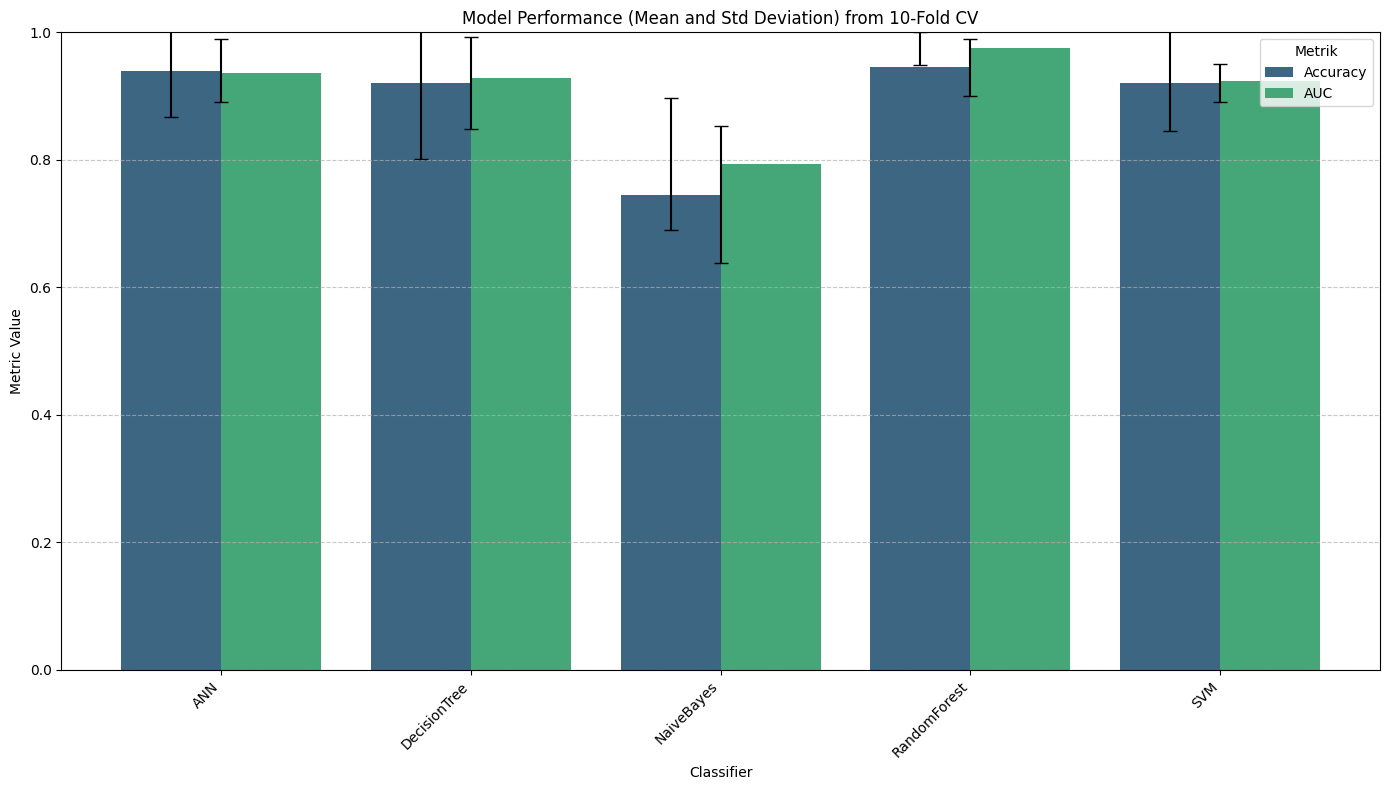

In [195]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Load the detailed 10-fold CV results DataFrame
cv_10fold_detailed_results_df = pd.read_excel("model_evaluation_results_10fold_cv_per_fold_cca.xlsx")

# Function to convert percentage strings to float for all relevant columns
def percentage_to_float_all_metrics(df, columns):
    df_numeric = df.copy()
    for col in columns:
        if col in df_numeric.columns:
            df_numeric[col] = df_numeric[col].astype(str).str.replace('%', '', regex=False).astype(float) / 100
    return df_numeric

# Define all metric columns that need to be converted to numeric
metric_cols = [
    "Accuracy", "Precision", "Sensitivity", "F1", "Specificity",
    "AUC", "Error_Rate", "FPR", "FNR"
]

# Convert all metric columns to numeric
cv_results_numeric = percentage_to_float_all_metrics(cv_10fold_detailed_results_df, metric_cols)

# Group by Classifier and calculate mean and standard deviation for each metric
mean_metrics_cv = cv_results_numeric.groupby('Classifier')[metric_cols].mean()
std_metrics_cv = cv_results_numeric.groupby('Classifier')[metric_cols].std()

# Select the metrics you want to visualize
metrics_to_plot = ['Accuracy', 'AUC']

# Combine the mean and std into a single DataFrame to facilitate plotting
plot_df = mean_metrics_cv[metrics_to_plot].stack().reset_index()
plot_df.columns = ['Classifier', 'Metric', 'Mean_Value']

# Add the standard deviation value
std_values = std_metrics_cv[metrics_to_plot].stack().reset_index()
std_values.columns = ['Classifier', 'Metric', 'Std_Value']

plot_df = pd.merge(plot_df, std_values, on=['Classifier', 'Metric'])

# Create a plot
plt.figure(figsize=(14, 8))
sns.barplot(
    x='Classifier',
    y='Mean_Value',
    hue='Metric',
    data=plot_df,
    palette='viridis',
    errorbar=None
)

for i, (classifier, group) in enumerate(plot_df.groupby('Classifier')):
    for j, (metric, row) in enumerate(group.groupby('Metric')):
        # Determining the position of the stem
        bar_position = i - (len(metrics_to_plot) / 2) * 0.2 + j * 0.2
        plt.errorbar(
            bar_position,
            row['Mean_Value'],
            yerr=row['Std_Value'],
            fmt='none',
            color='black',
            capsize=5
        )

plt.title('Model Performance (Mean and Std Deviation) from 10-Fold CV')
plt.xlabel('Classifier')
plt.ylabel('Metric Value')
plt.ylim(0, 1) # A metric scale is typically between 0 and 1
plt.xticks(rotation=45, ha='right')
plt.legend(title='Metrik')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [196]:
from sklearn.model_selection import ParameterSampler

for model_name, (model, param_grid) in models_param.items():
    print(f"\n--- Model: {model_name} ---")
    if len(param_grid) > 0:
        # ParameterSampler allows us to get the actual sampled parameters
        # We use a dummy estimator just to get the sampler working
        dummy_pipe = SkPipeline(steps=[("clf", model)])
        param_sampler = list(ParameterSampler(
            param_distributions=param_grid,
            n_iter=5, # Requesting 5 samples
            random_state=RANDOM_STATE # Ensure reproducibility for sampling
        ))
        for i, params in enumerate(param_sampler):
            print(f"  Kombinasi {i+1}: {params}")
    else:
        print(" No `param_grid` is defined for this model.")


--- Model: RandomForest ---
  Kombinasi 1: {'clf__n_estimators': 600, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 1, 'clf__max_features': 'sqrt', 'clf__max_depth': 20}
  Kombinasi 2: {'clf__n_estimators': 400, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 2, 'clf__max_features': 'sqrt', 'clf__max_depth': None}
  Kombinasi 3: {'clf__n_estimators': 400, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 1, 'clf__max_features': 'sqrt', 'clf__max_depth': None}
  Kombinasi 4: {'clf__n_estimators': 600, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 2, 'clf__max_features': 'sqrt', 'clf__max_depth': 20}
  Kombinasi 5: {'clf__n_estimators': 600, 'clf__min_samples_split': 2, 'clf__min_samples_leaf': 2, 'clf__max_features': 'log2', 'clf__max_depth': 10}

--- Model: DecisionTree ---
  Kombinasi 1: {'clf__min_samples_split': 5, 'clf__max_depth': 20}
  Kombinasi 2: {'clf__min_samples_split': 2, 'clf__max_depth': 20}
  Kombinasi 3: {'clf__min_samples_split': 2, 'clf__max

In [197]:
from sklearn.model_selection import ParameterSampler
import pandas as pd

sampled_params_list = []

print("\nCollecting 5 sampled hyperparameter combinations for each model...")

for model_name, (model, param_grid) in models_param.items():
    if len(param_grid) > 0:
        dummy_pipe = SkPipeline(steps=[("clf", model)])
        param_sampler = list(ParameterSampler(
            param_distributions=param_grid,
            n_iter=5, # Requesting 5 samples
            random_state=RANDOM_STATE # Ensure reproducibility for sampling
        ))
        for i, params in enumerate(param_sampler):
            # Prepend model name and combination number to each dictionary
            sampled_params_list.append({
                "Model": model_name,
                "Combination": i + 1,
                **params
            })
    else:
        sampled_params_list.append({
            "Model": model_name,
            "Combination": 1, # Even if no params, record it
            "Note": "Tidak ada `param_grid` yang didefinisikan untuk model ini."
        })

# Convert the list of sampled parameters to a DataFrame
sampled_params_df = pd.DataFrame(sampled_params_list)

# Save the DataFrame to an Excel file
output_filename = "sampled_hyperparameters.xlsx"
sampled_params_df.to_excel(output_filename, index=False)

print(f"\n5 sampled hyperparameter combinations for each model saved to '{output_filename}'.")
display(sampled_params_df.head(5))



5 sampled hyperparameter combinations for each model saved to 'sampled_hyperparameters.xlsx'.


,Model,Combination,clf__n_estimators,clf__min_samples_split,clf__min_samples_leaf,clf__max_features,clf__max_depth,clf__kernel,clf__gamma,clf__C,clf__var_smoothing,clf__hidden_layer_sizes,clf__alpha,clf__activation
0,RandomForest,1,600.0,5.0,1.0,sqrt,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,RandomForest,2,400.0,5.0,2.0,sqrt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,RandomForest,3,400.0,5.0,1.0,sqrt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,RandomForest,4,600.0,5.0,2.0,sqrt,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,RandomForest,5,600.0,2.0,2.0,log2,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [198]:
import warnings
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import RandomizedSearchCV
from sklearn.exceptions import ConvergenceWarning
import pandas as pd # Ensure pandas is imported for DataFrame operations
import numpy as np # Import numpy for np.nan

warnings.filterwarnings("ignore", category=ConvergenceWarning)

test_results = []

print(f"\n===================================")
print(f"=== Model Evaluation on Test Data ===")
print(f"=====================================")

# Define the preprocessor for no imputation scenario (same as training)
# Numeric pipeline: only scaling
numeric_transformer = SkPipeline(steps=[
    ("scaler", StandardScaler())
])

# Categorical pipeline: only OneHot (dense)
categorical_transformer = SkPipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder='passthrough'
)

# Dictionary to store the best trained model for each classifier
best_trained_models = {}

for model_name, (model, param_grid) in models_param.items():
    print(f"\n--> Training and Evaluating: Classifier={model_name} on Test Data")

    pipe = SkPipeline(steps=[
        ("preprocess", preprocessor),
        ("clf", model)
    ])

    try:
        best_model_for_test_evaluation = None
        best_params_for_test = {} # Initialize to store best parameters
        cv_roc_auc_for_test = np.nan # Initialize to store CV ROC AUC

        if len(param_grid) > 0:
            # Retrain (or get best estimator) using X_train to get a final model
            search = RandomizedSearchCV(
                estimator=pipe,
                param_distributions=param_grid,
                n_iter=5,
                cv=3,
                scoring="roc_auc",
                n_jobs=-1,
                random_state=RANDOM_STATE,
                error_score="raise"
            )
            search.fit(X_train, y_train)
            best_model_for_test_evaluation = search.best_estimator_
            best_params_for_test = search.best_params_
            cv_roc_auc_for_test = search.best_score_
        else:
            # If no param_grid, fit the pipeline directly on X_train
            best_model_for_test_evaluation = pipe.fit(X_train, y_train)
            best_params_for_test = {"Note": "No param_grid defined"}
            cv_roc_auc_for_test = np.nan # Not applicable if no param_grid was used with RandomizedSearchCV

        # Store the trained model (optional, but good for inspection if needed later)
        best_trained_models[model_name] = best_model_for_test_evaluation

        # Predict on the test data
        y_pred_test = best_model_for_test_evaluation.predict(X_test)
        if hasattr(best_model_for_test_evaluation.named_steps["clf"], "predict_proba"):
            y_proba_test = best_model_for_test_evaluation.predict_proba(X_test)
        else:
            y_proba_test = None

        # Compute metrics on the test data
        metrics_test = compute_metrics(y_test, y_pred_test, y_proba_test)

        test_results.append({
            "Classifier": model_name,
            "Accuracy": metrics_test["Accuracy"],
            "Precision": metrics_test["Precision"],
            "Sensitivity": metrics_test["Sensitivity"],
            "F1": metrics_test["F1"],
            "Specificity": metrics_test["Specificity"],
            "AUC": metrics_test["AUC"],
            "Error_Rate": metrics_test["Error_Rate"],
            "FPR": metrics_test["FPR"],
            "FNR": metrics_test["FNR"],
            "Best_Params": str(best_params_for_test),
            "CV_ROC_AUC": cv_roc_auc_for_test
        })

        print(f"   ✔ Done : {model_name} (Accuracy={metrics_test['Accuracy']:.4f}, AUC={metrics_test['AUC']:.4f})")

    except Exception as e:
        print(f"   Error pada Classifier {model_name} saat evaluasi (Test Data): {e}")
        continue

# Convert results to DataFrame
test_results_df = pd.DataFrame(test_results)

# Format relevant columns as percentages
percentage_cols = [
    "Accuracy", "Precision", "Sensitivity", "F1", "Specificity",
    "AUC", "Error_Rate", "FPR", "FNR", "CV_ROC_AUC"
]

for col in percentage_cols:
    if col in test_results_df.columns:
        test_results_df[col] = pd.to_numeric(test_results_df[col], errors='coerce')
        test_results_df[col] = test_results_df[col].apply(lambda x: f"{x:.2%}" if pd.notna(x) else x)

print("\nModel Performance Metrics on Test Data (No Imputation):")
display(test_results_df)

# Save the test results to an Excel file
test_results_df.to_excel("model_evaluation_results_test_data_no_imputation_cca.xlsx", index=False)
print("\nTest performance results saved to 'model_evaluation_results_test_data_no_imputation_cca.xlsx'.")


=== Model Evaluation on Test Data ===

--> Training and Evaluating: Classifier=RandomForest on Test Data
   ✔ Done : RandomForest (Accuracy=0.9286, AUC=1.0000)

--> Training and Evaluating: Classifier=DecisionTree on Test Data
   ✔ Done : DecisionTree (Accuracy=0.8571, AUC=0.8375)

--> Training and Evaluating: Classifier=SVM on Test Data
   ✔ Done : SVM (Accuracy=1.0000, AUC=1.0000)

--> Training and Evaluating: Classifier=NaiveBayes on Test Data
   ✔ Done : NaiveBayes (Accuracy=0.7857, AUC=0.7750)

--> Training and Evaluating: Classifier=ANN on Test Data
   ✔ Done : ANN (Accuracy=0.9286, AUC=0.9500)

Model Performance Metrics on Test Data (No Imputation):


,Classifier,Accuracy,Precision,Sensitivity,F1,Specificity,AUC,Error_Rate,FPR,FNR,Best_Params,CV_ROC_AUC
0,RandomForest,92.86%,100.00%,75.00%,85.71%,100.00%,100.00%,7.14%,0.00%,25.00%,"{'clf__n_estimators': 400, 'clf__min_samples_s...",97.27%
1,DecisionTree,85.71%,75.00%,75.00%,75.00%,90.00%,83.75%,14.29%,10.00%,25.00%,"{'clf__min_samples_split': 10, 'clf__max_depth...",96.72%
2,SVM,100.00%,100.00%,100.00%,100.00%,100.00%,100.00%,0.00%,0.00%,0.00%,"{'clf__kernel': 'rbf', 'clf__gamma': 'scale', ...",92.61%
3,NaiveBayes,78.57%,60.00%,75.00%,66.67%,80.00%,77.50%,21.43%,20.00%,25.00%,{'clf__var_smoothing': np.float64(1.6297508346...,77.56%
4,ANN,92.86%,80.00%,100.00%,88.89%,90.00%,95.00%,7.14%,10.00%,0.00%,"{'clf__hidden_layer_sizes': (50, 50), 'clf__al...",85.72%



Test performance results saved to 'model_evaluation_results_test_data_no_imputation_cca.xlsx'.



=== Confusion Matrices on Test Data ===

--- Classifier: RandomForest ---


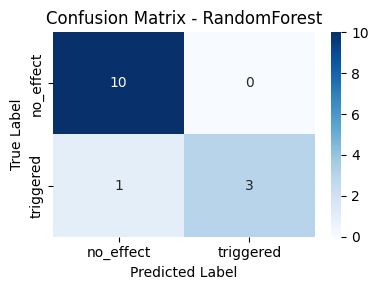


--- Classifier: DecisionTree ---


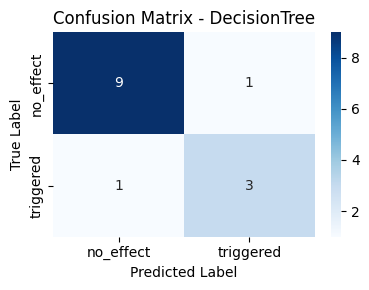


--- Classifier: SVM ---


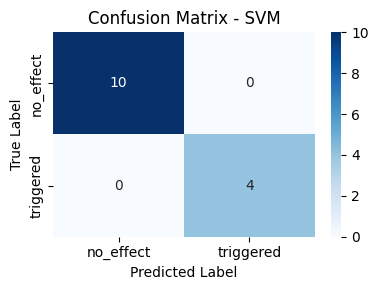


--- Classifier: NaiveBayes ---


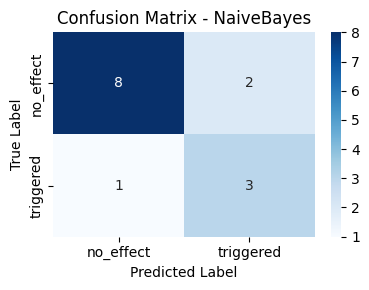


--- Classifier: ANN ---


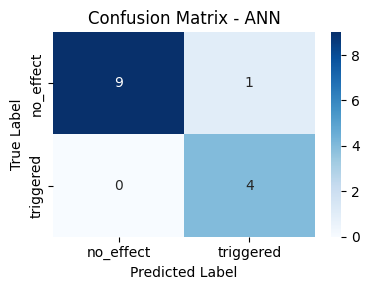

In [199]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming best_trained_models contains the fitted pipelines and X_test, y_test are available

print("\n=========================================")
print("=== Confusion Matrices on Test Data ===")
print("===========================================")

for model_name, best_model in best_trained_models.items():
    print(f"\n--- Classifier: {model_name} ---")

    # Predict on the test data
    y_pred_test = best_model.predict(X_test)

    # Get unique classes, ensuring consistent order for confusion matrix
    classes = sorted(y_test.unique())

    # Calculate Confusion Matrix
    cm = confusion_matrix(y_test, y_pred_test, labels=classes)

    # Display Confusion Matrix using seaborn and matplotlib
    plt.figure(figsize=(4, 3))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=classes,
        yticklabels=classes
    )
    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.tight_layout()
    plt.show()

In [201]:
# Determining the Best Model Based on the Highest Average Accuracy from Nested Stratified Cross-Validation

import pandas as pd
import numpy as np

# Load the detailed 10-fold CV results DataFrame using the correct filename
cv_results_df = pd.read_excel("model_evaluation_results_10fold_cv_per_fold_cca.xlsx")

# Function to convert percentage strings to float
def percentage_to_float_col(series):
    # Ensure the series is treated as strings, then remove '%' and convert to float
    return series.astype(str).str.replace('%', '', regex=False).astype(float) / 100

# Convert 'Accuracy' column to numeric for calculation
cv_results_df['Accuracy_Numeric'] = percentage_to_float_col(cv_results_df['Accuracy'])

# Calculate the average Accuracy for each classifier
average_accuracy_per_classifier = cv_results_df.groupby('Classifier')['Accuracy_Numeric'].mean().sort_values(ascending=False)

print("\n--- Average Accuracy per Classifier from 10-Fold CV ---")
display(average_accuracy_per_classifier.to_frame())

# Identify the best model based on highest average Accuracy
best_cv_accuracy_model_name = average_accuracy_per_classifier.index[0]
best_cv_accuracy_value = average_accuracy_per_classifier.iloc[0]

print(f"\nThe best model, based on the highest average accuracy from 10-fold CV, is: {best_cv_accuracy_model_name} with an average accuracy: {best_cv_accuracy_value:.2%}")


--- Average Accuracy per Classifier from 10-Fold CV ---


,Accuracy_Numeric
Classifier,
RandomForest,0.94523
ANN,0.93972
DecisionTree,0.92060
SVM,0.92060
NaiveBayes,0.74522



The best model, based on the highest average accuracy from 10-fold CV, is: RandomForest with an average accuracy: 94.52%


In [202]:
import pandas as pd
import numpy as np

# Automatically reading detailed cross-validation (CV) results to obtain the best AUC value
cv_results_df = pd.read_excel("model_evaluation_results_10fold_cv_per_fold_cca.xlsx")

def percentage_to_float_col(series):
    return series.astype(str).str.replace('%', '', regex=False).astype(float) / 100

# Find the best average AUC
cv_results_df['AUC_Numeric'] = percentage_to_float_col(cv_results_df['AUC'])
average_auc_per_classifier = cv_results_df.groupby('Classifier')['AUC_Numeric'].mean().sort_values(ascending=False)
best_cv_auc_model_name = average_auc_per_classifier.index[0]
best_cv_auc_value = average_auc_per_classifier.iloc[0]

# Use the best accuracy variable already in memory (or recalculate if necessary)
if 'best_cv_accuracy_model_name' not in globals():
    cv_results_df['Accuracy_Numeric'] = percentage_to_float_col(cv_results_df['Accuracy'])
    average_accuracy_per_classifier = cv_results_df.groupby('Classifier')['Accuracy_Numeric'].mean().sort_values(ascending=False)
    best_cv_accuracy_model_name = average_accuracy_per_classifier.index[0]
    best_cv_accuracy_value = average_accuracy_per_classifier.iloc[0]

output_excel_file_cv = "best_cv_model_based_on_metrics.xlsx"

with pd.ExcelWriter(output_excel_file_cv) as writer:
    # Create a DataFrame for the best AUC model
    best_auc_cv_df = pd.DataFrame({
        'Classifier': [best_cv_auc_model_name],
        'Average_AUC': [f"{best_cv_auc_value:.2%}"]
    })
    best_auc_cv_df.to_excel(writer, sheet_name='Best_CV_AUC_Model', index=False)

    # Create a DataFrame for the best Accuracy model
    best_accuracy_cv_df = pd.DataFrame({
        'Classifier': [best_cv_accuracy_model_name],
        'Average_Accuracy': [f"{best_cv_accuracy_value:.2%}"]
    })
    best_accuracy_cv_df.to_excel(writer, sheet_name='Best_CV_Accuracy_Model', index=False)

print(f"The best model details from 10-fold CV have been saved to '{output_excel_file_cv}'.")

The best model details from 10-fold CV have been saved to 'best_cv_model_based_on_metrics.xlsx'.


In [203]:
import pandas as pd
import numpy as np

# Load the detailed 10-fold CV results DataFrame
cv_10fold_detailed_results_df = pd.read_excel("model_evaluation_results_10fold_cv_per_fold_cca.xlsx")

# Function to convert percentage strings to float for all relevant columns
def percentage_to_float_all_metrics(df, columns):
    df_numeric = df.copy()
    for col in columns:
        if col in df_numeric.columns:
            df_numeric[col] = df_numeric[col].astype(str).str.replace('%', '', regex=False).astype(float) / 100
    return df_numeric

# Define all metric columns that need to be converted to numeric
metric_cols = [
    "Accuracy", "Precision", "Sensitivity", "F1", "Specificity",
    "AUC", "Error_Rate", "FPR", "FNR"
]

# Convert all metric columns to numeric
cv_results_numeric = percentage_to_float_all_metrics(cv_10fold_detailed_results_df, metric_cols)

# Group by Classifier and calculate mean and standard deviation for each metric
mean_metrics_cv = cv_results_numeric.groupby('Classifier')[metric_cols].mean()
std_metrics_cv = cv_results_numeric.groupby('Classifier')[metric_cols].std()

print("\n--- Average Metrics from 10-Fold CV per Classifier ---")
display(mean_metrics_cv.map(lambda x: f"{x:.2%}" if pd.notna(x) else np.nan))

print("\n--- Metric Standard Deviation from 10-Fold CV per Classifier ---")
display(std_metrics_cv.map(lambda x: f"{x:.2%}" if pd.notna(x) else np.nan))

# Save the mean and std deviation results to separate sheets in an Excel file
output_excel_file_summary_cv = "summary_results_of_metrics_10fold_cv.xlsx"

with pd.ExcelWriter(output_excel_file_summary_cv) as writer:
    # Save mean metrics
    mean_metrics_cv.to_excel(writer, sheet_name='Mean_Metrics_CV')

    # Save standard deviation metrics
    std_metrics_cv.to_excel(writer, sheet_name='Std_Dev_Metrics_CV')

print(f"\nThe summary of the mean and standard deviation metrics from the 10-fold CV has been saved to '{output_excel_file_summary_cv}'.")


--- Average Metrics from 10-Fold CV per Classifier ---


,Accuracy,Precision,Sensitivity,F1,Specificity,AUC,Error_Rate,FPR,FNR
Classifier,,,,,,,,,
ANN,93.97%,93.24%,88.67%,89.80%,96.44%,93.70%,6.03%,3.56%,11.33%
DecisionTree,92.06%,93.00%,82.67%,84.72%,96.44%,92.80%,7.94%,3.56%,17.33%
NaiveBayes,74.52%,57.28%,94.33%,70.88%,65.23%,79.41%,25.48%,34.77%,5.67%
RandomForest,94.52%,95.48%,88.67%,91.31%,97.27%,97.47%,5.48%,2.73%,11.33%
SVM,92.06%,91.33%,84.67%,86.86%,95.53%,92.36%,7.94%,4.47%,15.33%



--- Metric Standard Deviation from 10-Fold CV per Classifier ---


,Accuracy,Precision,Sensitivity,F1,Specificity,AUC,Error_Rate,FPR,FNR
Classifier,,,,,,,,,
ANN,4.91%,8.84%,15.73%,9.02%,4.60%,6.97%,4.91%,4.60%,15.73%
DecisionTree,7.23%,9.09%,23.92%,19.10%,4.60%,12.67%,7.23%,4.60%,23.92%
NaiveBayes,10.76%,12.16%,9.17%,10.71%,13.60%,10.34%,10.76%,13.60%,9.17%
RandomForest,4.48%,9.94%,9.84%,6.48%,6.14%,2.59%,4.48%,6.14%,9.84%
SVM,2.99%,9.19%,12.49%,5.56%,4.72%,7.91%,2.99%,4.72%,12.49%



The summary of the mean and standard deviation metrics from the 10-fold CV has been saved to 'summary_results_of_metrics_10fold_cv.xlsx'.


In [204]:
import pandas as pd

# Reading an independent test data file
test_data = pd.read_csv('LTCDAR3_TEST.csv')

# Calculating the number of missing values ​​per column
missing_per_col = test_data.isnull().sum()
total_missing = test_data.isnull().sum().sum()

print("--- Informasi Missing Value pada LTCDAR3_TEST.csv ---")
print(f"Total number of missing values: {total_missing}")
print("\nDetails of missing values ​​per column:")
print(missing_per_col[missing_per_col > 0])

# Counting how many rows (samples) contain at least one missing value
missing_rows = test_data.isnull().any(axis=1).sum()
print(f"\nNumber of rows (samples) that have at least one missing value: {missing_rows} from {len(test_data)} total rows.")

--- Informasi Missing Value pada LTCDAR3_TEST.csv ---
Total number of missing values: 20

Details of missing values ​​per column:
Shape                             5
Zeta Potential (mV)              10
Specific surface area (m2/g)      5
dtype: int64

Number of rows (samples) that have at least one missing value: 10 from 19 total rows.


In [206]:
# PFI (PCS) CALCULATION FUNCTION
from sklearn.metrics import accuracy_score
import numpy as np

def compute_pfi(model, X, y, n_repeats=3):
    baseline = accuracy_score(y, model.predict(X))
    N, F = X.shape
    pfi = np.zeros(F)

    for j in range(F):
        perm_scores = []
        for _ in range(n_repeats):
            X_perm = X.copy()
            np.random.shuffle(X_perm[:, j])
            perm_acc = accuracy_score(y, model.predict(X_perm))
            perm_scores.append(perm_acc)

        pfi[j] = baseline - np.mean(perm_scores)

    PCS = pfi.mean()
    return PCS, baseline

In [207]:
#PFI per Combination (I/F)
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

def compute_pfi(model, X, y, n_repeats=3):
    """
    model : trained classifier (only classifier, not pipeline)
    X : preprocessed numpy array
    y : true labels
    n_repeats : number of permutations per feature
    """
    baseline = accuracy_score(y, model.predict(X))

    N, F = X.shape
    pfi = np.zeros(F)

    for j in range(F):
        perm_scores = []
        for _ in range(n_repeats):
            X_perm = X.copy()
            np.random.shuffle(X_perm[:, j])  # permute feature j
            perm_acc = accuracy_score(y, model.predict(X_perm))
            perm_scores.append(perm_acc)

        pfi[j] = baseline - np.mean(perm_scores)

    return pfi, baseline

In [208]:
import numpy as np

#Calculating PFI for all combinations (5 classifiers)
pfi_results = []

# Assuming this section is for 'No Imputation' or 'CCA' context
# The best_trained_models keys are classifier names, not (imp, clf) tuples.
# So, we'll manually assign 'CCA' as the imputation method.
imp_method = "CCA"

for clf_name, model in best_trained_models.items():

    preprocess = model.named_steps["preprocess"]
    clf_model = model.named_steps["clf"]

    X_pre = preprocess.transform(X_train)

    # Compute PFI
    pfi_values, baseline_acc = compute_pfi(clf_model, X_pre, y_train)

    # Aggregate into a single value (Permutation Combination Score)
    PCS = np.mean(pfi_values)

    pfi_results.append({
        "Imputation": imp_method,
        "Classifier": clf_name,
        "Combination": f"{imp_method} + {clf_name}",
        "BaselineAccuracy": baseline_acc,
        "PermutationCombinationScore": PCS,
        "NumFeatures": X_pre.shape[1]
    })

In [143]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, accuracy_score, matthews_corrcoef
from sklearn.base import clone
from sklearn.impute import SimpleImputer # Import SimpleImputer

def compute_pfi(model_pipeline, X_original, y_true, feature_names_original, scoring_metric='roc_auc'):

    preprocessor = model_pipeline.named_steps["preprocess"]
    clf_model = model_pipeline.named_steps["clf"]

    # Transform X_original using the preprocessor to get the data the clf_model sees
    X_preprocessed_transformed = preprocessor.transform(X_original)

    imputer = SimpleImputer(strategy='mean')
    X_preprocessed_imputed = imputer.fit_transform(X_preprocessed_transformed)

    # Determine baseline score
    baseline_score = 0.0
    if scoring_metric == 'roc_auc':
        if hasattr(clf_model, 'predict_proba'):
            y_proba_baseline = clf_model.predict_proba(X_preprocessed_imputed)
            # Ensure y_true is binarized for roc_auc_score if not already
            y_true_bin = (y_true == POS_LABEL).astype(int) # Assuming POS_LABEL is defined
            baseline_score = roc_auc_score(y_true_bin, y_proba_baseline[:, 1])
        else:
            print(f"Warning: Model {type(clf_model).__name__} does not have predict_proba. Using accuracy for PFI.")
            y_pred_baseline = clf_model.predict(X_preprocessed_imputed)
            baseline_score = accuracy_score(y_true, y_pred_baseline)
            scoring_metric = 'accuracy' # Adjust scoring metric if fallback
    elif scoring_metric == 'accuracy':
        y_pred_baseline = clf_model.predict(X_preprocessed_imputed)
        baseline_score = accuracy_score(y_true, y_pred_baseline)
    elif scoring_metric == 'mcc':
        y_pred_baseline = clf_model.predict(X_preprocessed_imputed)
        baseline_score = matthews_corrcoef(y_true, y_pred_baseline)
    else:
        raise ValueError(f"Unsupported scoring_metric: {scoring_metric}")

    pfi_values = []
    for feature_name in feature_names_original:
        # Create a copy of the original data to permute
        X_permuted = X_original.copy()

        # Permute the current feature's values in the ORIGINAL data
        X_permuted[feature_name] = X_permuted[feature_name].sample(
            frac=1, random_state=RANDOM_STATE
        ).reset_index(drop=True)

        # Transform the permuted original data using the same preprocessor
        X_permuted_preprocessed_transformed = preprocessor.transform(X_permuted)

        # Impute the permuted preprocessed data using the *fitted* imputer
        X_permuted_preprocessed_imputed = imputer.transform(X_permuted_preprocessed_transformed)

        # Calculate score with permuted feature
        permuted_score = 0.0
        if scoring_metric == 'roc_auc':
            if hasattr(clf_model, 'predict_proba'):
                y_proba_permuted = clf_model.predict_proba(X_permuted_preprocessed_imputed)
                y_true_bin = (y_true == POS_LABEL).astype(int) # Assuming POS_LABEL is defined
                permuted_score = roc_auc_score(y_true_bin, y_proba_permuted[:, 1])
            else:
                y_pred_permuted = clf_model.predict(X_permuted_preprocessed_imputed)
                permuted_score = accuracy_score(y_true, y_pred_permuted)
        elif scoring_metric == 'accuracy':
            y_pred_permuted = clf_model.predict(X_permuted_preprocessed_imputed)
            permuted_score = accuracy_score(y_true, y_pred_permuted)
        elif scoring_metric == 'mcc':
            y_pred_permuted = clf_model.predict(X_permuted_preprocessed_imputed)
            permuted_score = matthews_corrcoef(y_true, y_pred_permuted)

        # Importance is the drop in score
        importance = baseline_score - permuted_score
        pfi_values.append({'Feature': feature_name, 'Importance': importance})

    return pd.DataFrame(pfi_values).sort_values(by='Importance', ascending=False), baseline_score


In [210]:
import warnings
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import RandomizedSearchCV
from sklearn.exceptions import ConvergenceWarning
import pandas as pd
import numpy as np

warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Memastikan kita menggunakan fungsi compute_pfi versi terbaru yang mendukung scoring_metric dari cell 2cX119kesphH
# Fungsi ini dideklarasikan ulang di sini untuk menghindari tabrakan namespace di kernel state
from sklearn.metrics import roc_auc_score, accuracy_score, matthews_corrcoef
from sklearn.impute import SimpleImputer

def compute_pfi(model_pipeline, X_original, y_true, feature_names_original, scoring_metric='roc_auc'):
    preprocessor = model_pipeline.named_steps["preprocess"]
    clf_model = model_pipeline.named_steps["clf"]

    X_preprocessed_transformed = preprocessor.transform(X_original)
    imputer = SimpleImputer(strategy='mean')
    X_preprocessed_imputed = imputer.fit_transform(X_preprocessed_transformed)

    baseline_score = 0.0
    if scoring_metric == 'roc_auc':
        if hasattr(clf_model, 'predict_proba'):
            y_proba_baseline = clf_model.predict_proba(X_preprocessed_imputed)
            y_true_bin = (y_true == POS_LABEL).astype(int)
            baseline_score = roc_auc_score(y_true_bin, y_proba_baseline[:, 1])
        else:
            y_pred_baseline = clf_model.predict(X_preprocessed_imputed)
            baseline_score = accuracy_score(y_true, y_pred_baseline)
            scoring_metric = 'accuracy'
    elif scoring_metric == 'accuracy':
        y_pred_baseline = clf_model.predict(X_preprocessed_imputed)
        baseline_score = accuracy_score(y_true, y_pred_baseline)
    elif scoring_metric == 'mcc':
        y_pred_baseline = clf_model.predict(X_preprocessed_imputed)
        baseline_score = matthews_corrcoef(y_true, y_pred_baseline)

    pfi_values = []
    for feature_name in feature_names_original:
        X_permuted = X_original.copy()
        X_permuted[feature_name] = X_permuted[feature_name].sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
        X_permuted_preprocessed_transformed = preprocessor.transform(X_permuted)
        X_permuted_preprocessed_imputed = imputer.transform(X_permuted_preprocessed_transformed)

        permuted_score = 0.0
        if scoring_metric == 'roc_auc':
            if hasattr(clf_model, 'predict_proba'):
                y_proba_permuted = clf_model.predict_proba(X_permuted_preprocessed_imputed)
                y_true_bin = (y_true == POS_LABEL).astype(int)
                permuted_score = roc_auc_score(y_true_bin, y_proba_permuted[:, 1])
            else:
                y_pred_permuted = clf_model.predict(X_permuted_preprocessed_imputed)
                permuted_score = accuracy_score(y_true, y_pred_permuted)
        elif scoring_metric == 'accuracy':
            y_pred_permuted = clf_model.predict(X_permuted_preprocessed_imputed)
            permuted_score = accuracy_score(y_true, y_pred_permuted)
        elif scoring_metric == 'mcc':
            y_pred_permuted = clf_model.predict(X_permuted_preprocessed_imputed)
            permuted_score = matthews_corrcoef(y_true, y_pred_permuted)

        importance = baseline_score - permuted_score
        pfi_values.append({'Feature': feature_name, 'Importance': importance})

    return pd.DataFrame(pfi_values).sort_values(by='Importance', ascending=False), baseline_score

pfi_ncv_results = []

print(f"\n======================================================")
print(f"=== Permutation Feature Importance (Nested CV - Per Fold) ===")
print(f"======================================================")

numeric_transformer = SkPipeline(steps=[("scaler", StandardScaler())])
categorical_transformer = SkPipeline(steps=[("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder='passthrough'
)

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
best_classifiers_for_pfi = list(models_param.keys())

for model_name in best_classifiers_for_pfi:
    model, param_grid = models_param[model_name]
    print(f"\n--> Calculating PFI for {model_name} across 10-Fold CV")

    pipe = SkPipeline(steps=[
        ("preprocess", preprocessor),
        ("clf", model)
    ])

    for fold_idx, (train_index, val_index) in enumerate(skf.split(X_train, y_train)):
        X_fold_train, X_fold_val = X_train.iloc[train_index], X_train.iloc[val_index]
        y_fold_train, y_fold_val = y_train.iloc[train_index], y_train.iloc[val_index]

        try:
            best_model_for_fold = None
            if len(param_grid) > 0:
                search_inner = RandomizedSearchCV(
                    estimator=pipe,
                    param_distributions=param_grid,
                    n_iter=5,
                    cv=3,
                    scoring="roc_auc",
                    n_jobs=-1,
                    random_state=RANDOM_STATE,
                    error_score="raise"
                )
                search_inner.fit(X_fold_train, y_fold_train)
                best_model_for_fold = search_inner.best_estimator_
            else:
                best_model_for_fold = pipe.fit(X_fold_train, y_fold_train)

            # Hitung PFI untuk metric 'accuracy'
            pfi_df_acc, baseline_acc = compute_pfi(
                best_model_for_fold,
                X_fold_val,
                y_fold_val,
                X_train.columns.tolist(),
                scoring_metric='accuracy'
            )
            pfi_ncv_results.append({
                "Classifier": model_name,
                "Fold": fold_idx + 1,
                "Scoring_Metric": "accuracy",
                "Baseline_Score": baseline_acc,
                "PFI_Results": pfi_df_acc.to_dict('records')
            })
            print(f"   Fold {fold_idx+1}/10 ({model_name} - Accuracy) Baseline: {baseline_acc:.4f}")

            # Hitung PFI untuk metric 'roc_auc'
            pfi_df_auc, baseline_auc = compute_pfi(
                best_model_for_fold,
                X_fold_val,
                y_fold_val,
                X_train.columns.tolist(),
                scoring_metric='roc_auc'
            )
            pfi_ncv_results.append({
                "Classifier": model_name,
                "Fold": fold_idx + 1,
                "Scoring_Metric": "roc_auc",
                "Baseline_Score": baseline_auc,
                "PFI_Results": pfi_df_auc.to_dict('records')
            })
            print(f"   Fold {fold_idx+1}/10 ({model_name} - ROC-AUC) Baseline: {baseline_auc:.4f}")

        except Exception as e:
            print(f"   ☢ Error calculating PFI for {model_name} during Fold {fold_idx+1}: {e}")
            pfi_ncv_results.append({
                "Classifier": model_name,
                "Fold": fold_idx + 1,
                "Scoring_Metric": "accuracy",
                "Baseline_Score": np.nan,
                "PFI_Results": []
            })
            pfi_ncv_results.append({
                "Classifier": model_name,
                "Fold": fold_idx + 1,
                "Scoring_Metric": "roc_auc",
                "Baseline_Score": np.nan,
                "PFI_Results": []
            })

print("\n--- Detailed PFI Results per Fold (Nested CV) ---")
flat_pfi_data = []
for res in pfi_ncv_results:
    for pfi_entry in res['PFI_Results']:
        flat_pfi_data.append({
            "Classifier": res['Classifier'],
            "Fold": res['Fold'],
            "Scoring_Metric": res['Scoring_Metric'],
            "Baseline_Score": res['Baseline_Score'],
            "Feature": pfi_entry['Feature'],
            "Importance": pfi_entry['Importance']
        })

detailed_pfi_ncv_df = pd.DataFrame(flat_pfi_data)
display(detailed_pfi_ncv_df.head())

print("\n--- Aggregated PFI Results (Mean & Std Dev across Folds) ---")
aggregated_pfi_ncv = detailed_pfi_ncv_df.groupby(['Classifier', 'Scoring_Metric', 'Feature'])['Importance'].agg(['mean', 'std']).reset_index()
display(aggregated_pfi_ncv.sort_values(by=['Classifier', 'Scoring_Metric', 'mean'], ascending=[True, True, False]).head())

output_excel_file_pfi_ncv = "pfi_results_ncv_best_models.xlsx"
with pd.ExcelWriter(output_excel_file_pfi_ncv) as writer:
    detailed_pfi_ncv_df.to_excel(writer, sheet_name='Detailed_PFI_NCV', index=False)
    aggregated_pfi_ncv.to_excel(writer, sheet_name='Aggregated_PFI_NCV', index=False)

print(f"PFI results for best models across NCV folds saved to '{output_excel_file_pfi_ncv}'.")


=== Permutation Feature Importance (Nested CV - Per Fold) ===

--> Calculating PFI for RandomForest across 10-Fold CV
   Fold 1/10 (RandomForest - Accuracy) Baseline: 0.9412
   Fold 1/10 (RandomForest - ROC-AUC) Baseline: 0.9500
   Fold 2/10 (RandomForest - Accuracy) Baseline: 1.0000
   Fold 2/10 (RandomForest - ROC-AUC) Baseline: 1.0000
   Fold 3/10 (RandomForest - Accuracy) Baseline: 0.8824
   Fold 3/10 (RandomForest - ROC-AUC) Baseline: 0.9545
   Fold 4/10 (RandomForest - Accuracy) Baseline: 0.9412
   Fold 4/10 (RandomForest - ROC-AUC) Baseline: 0.9697
   Fold 5/10 (RandomForest - Accuracy) Baseline: 0.9375
   Fold 5/10 (RandomForest - ROC-AUC) Baseline: 0.9273
   Fold 6/10 (RandomForest - Accuracy) Baseline: 1.0000
   Fold 6/10 (RandomForest - ROC-AUC) Baseline: 1.0000
   Fold 7/10 (RandomForest - Accuracy) Baseline: 0.8750
   Fold 7/10 (RandomForest - ROC-AUC) Baseline: 0.9636
   Fold 8/10 (RandomForest - Accuracy) Baseline: 0.9375
   Fold 8/10 (RandomForest - ROC-AUC) Baseline: 

,Classifier,Fold,Scoring_Metric,Baseline_Score,Feature,Importance
0,RandomForest,1,accuracy,0.941176,Exposure dose (μg/ml),0.294118
1,RandomForest,1,accuracy,0.941176,Cell line,0.176471
2,RandomForest,1,accuracy,0.941176,Nanoparticles,0.000000
3,RandomForest,1,accuracy,0.941176,Core size (nm),0.000000
4,RandomForest,1,accuracy,0.941176,Surface coatings,0.000000



--- Aggregated PFI Results (Mean & Std Dev across Folds) ---


,Classifier,Scoring_Metric,Feature,mean,std
0,ANN,accuracy,Cell line,0.250735,0.063603
3,ANN,accuracy,Exposure dose (μg/ml),0.231618,0.094195
5,ANN,accuracy,Microarray Method_Transcriptomics,0.226838,0.075585
6,ANN,accuracy,Nanoparticles,0.183456,0.052294
1,ANN,accuracy,Cell type,0.169853,0.078523


PFI results for best models across NCV folds saved to 'pfi_results_ncv_best_models.xlsx'.


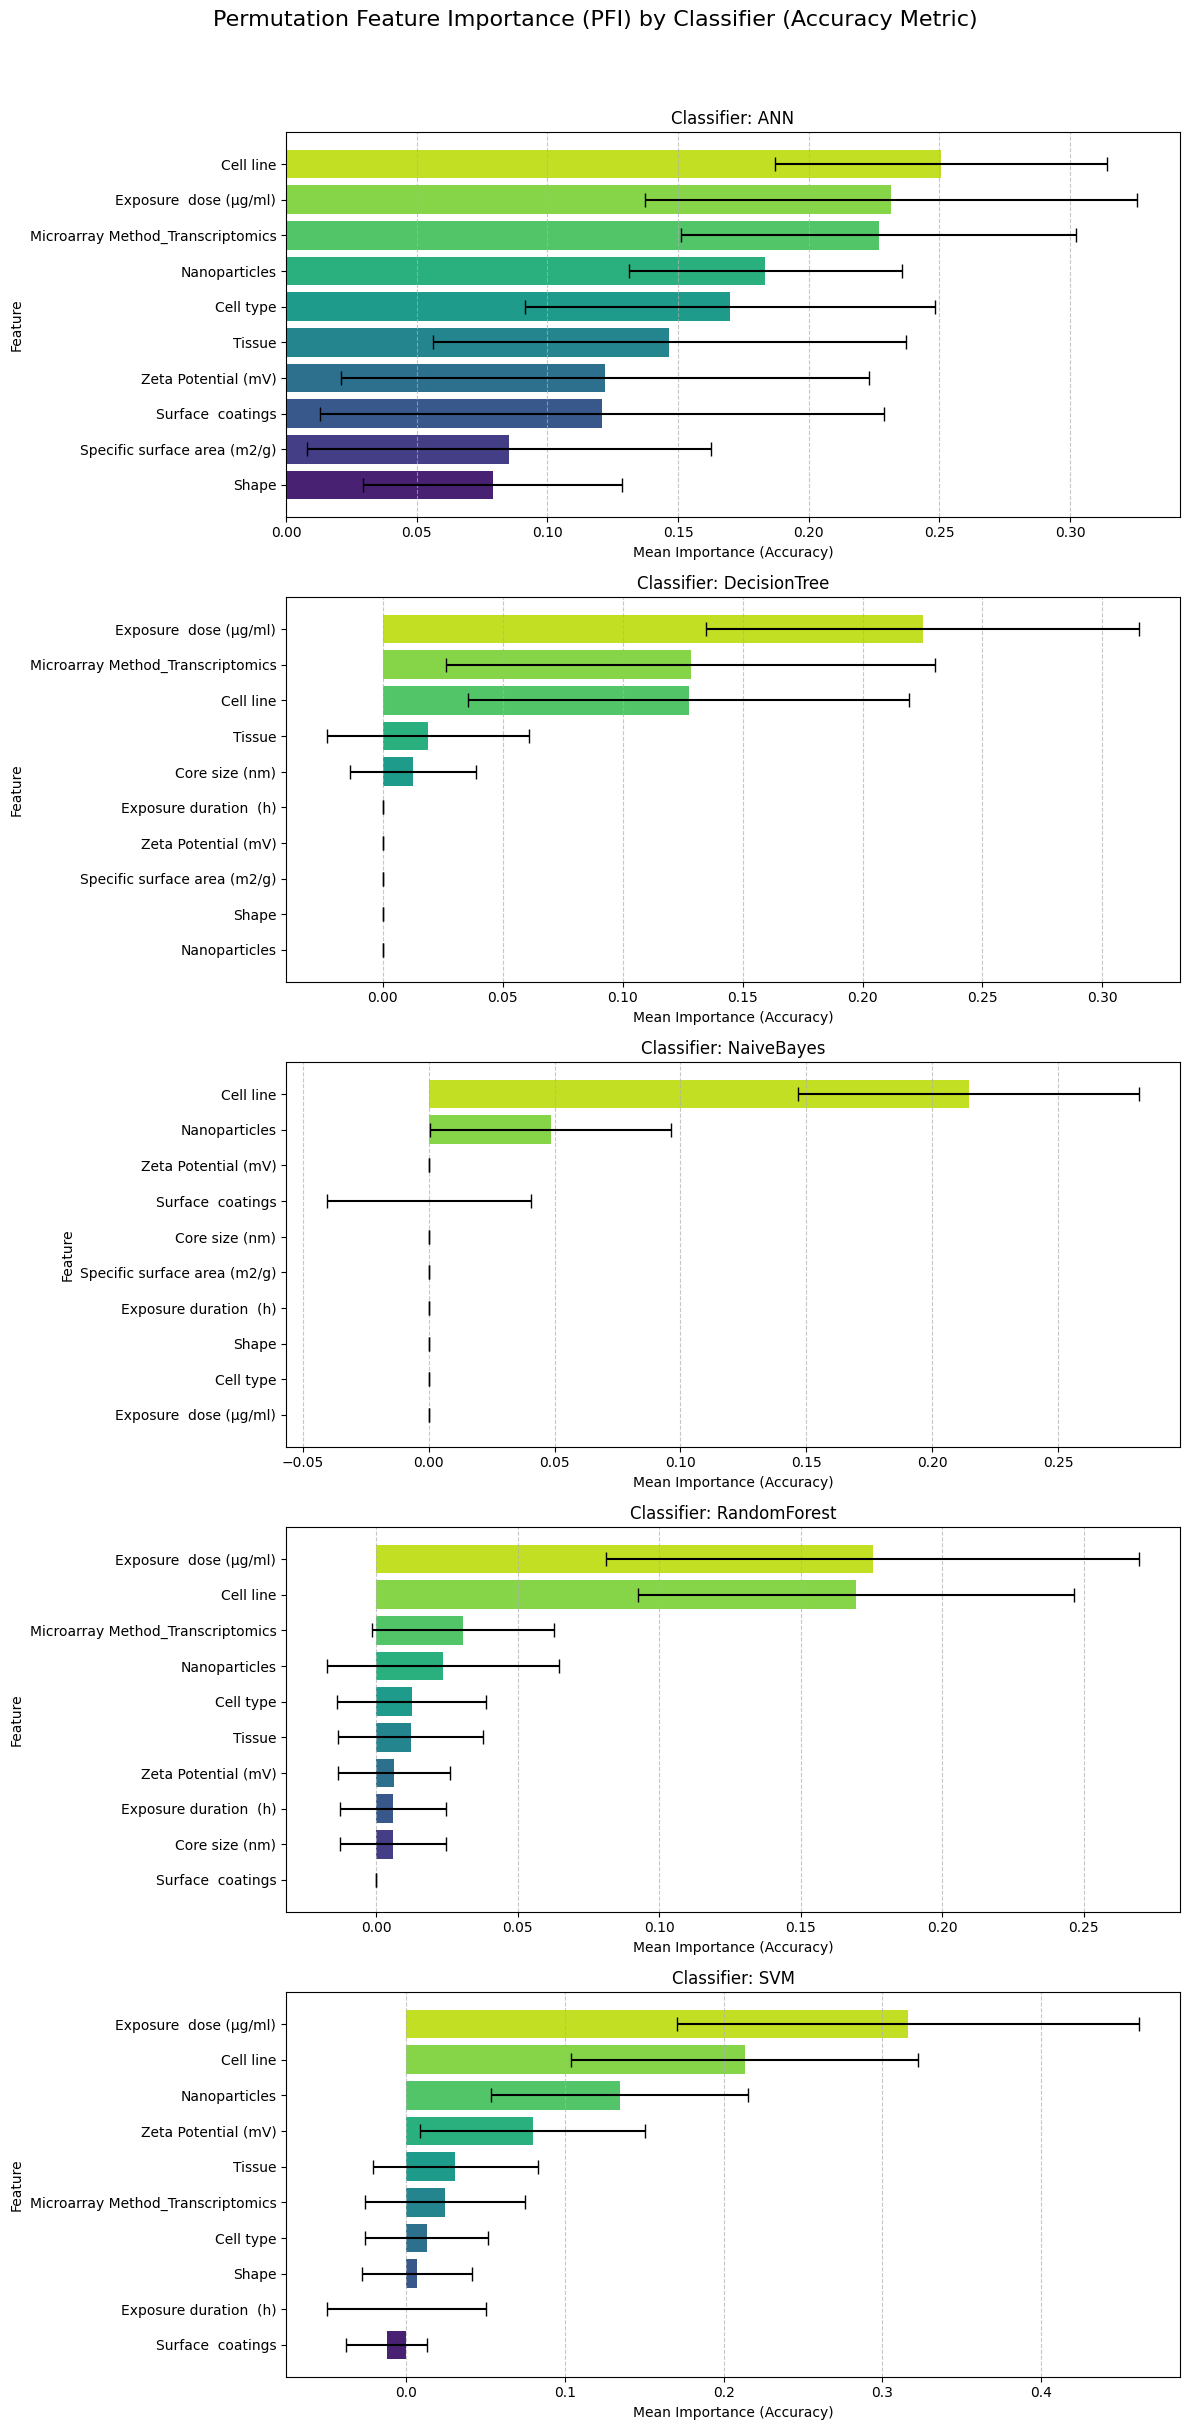

In [211]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Filter aggregated_pfi_ncv for the 'accuracy' metric only
pfi_accuracy_df = aggregated_pfi_ncv[
    aggregated_pfi_ncv['Scoring_Metric'] == 'accuracy'
].copy()

# Get a list of unique classifiers
classifiers = pfi_accuracy_df['Classifier'].unique()

# Plot configuration
num_classifiers = len(classifiers)
fig, axes = plt.subplots(num_classifiers, 1, figsize=(12, num_classifiers * 5), sharex=False)
fig.suptitle('Permutation Feature Importance (PFI) by Classifier (Accuracy Metric)', y=1.00, fontsize=16)

top_n_features = 10

for i, clf in enumerate(classifiers):
    # Filter for the current classifier and sort by average Importance
    clf_pfi_df = pfi_accuracy_df[
        pfi_accuracy_df['Classifier'] == clf
    ].sort_values(by='mean', ascending=True)

    # Take the top N features
    clf_pfi_df_top_n = clf_pfi_df.tail(top_n_features)

    # Plot using barh on the appropriate subplot
    ax = axes[i] if num_classifiers > 1 else axes
    ax.barh(
        y=clf_pfi_df_top_n['Feature'],
        width=clf_pfi_df_top_n['mean'],
        xerr=clf_pfi_df_top_n['std'], # Error bars untuk standar deviasi
        color=sns.color_palette("viridis", n_colors=len(clf_pfi_df_top_n)), # Warna dinamis
        capsize=5
    )
    ax.set_title(f'Classifier: {clf}')
    ax.set_xlabel('Mean Importance (Accuracy)')
    ax.set_ylabel('Feature')
    ax.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout(rect=[0, 0.03, 1, 0.98])
plt.show()

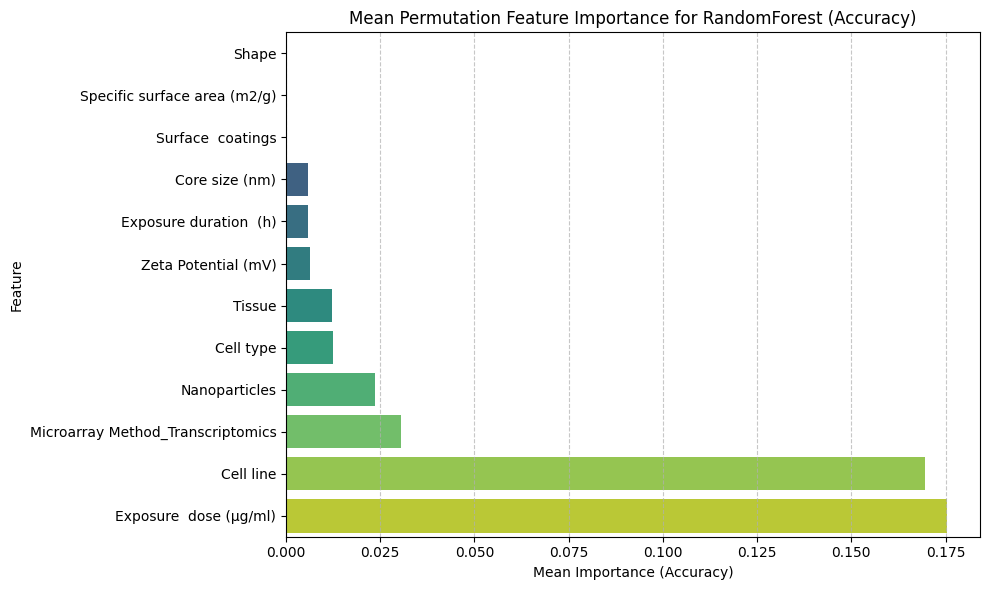

In [212]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Filter for RandomForest and accuracy metric
rf_pfi_accuracy = pfi_accuracy_df[
    pfi_accuracy_df['Classifier'] == 'RandomForest'
].copy()

# Sort by mean importance for better visualization
rf_pfi_accuracy_sorted_mean = rf_pfi_accuracy.sort_values(by='mean', ascending=True)

plt.figure(figsize=(10, 6))
sns.barplot(
    x='mean',
    y='Feature',
    data=rf_pfi_accuracy_sorted_mean,
    palette='viridis',
    hue='Feature',
    legend=False
)
plt.xlabel('Mean Importance (Accuracy)')
plt.ylabel('Feature')
plt.title('Mean Permutation Feature Importance for RandomForest (Accuracy)')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

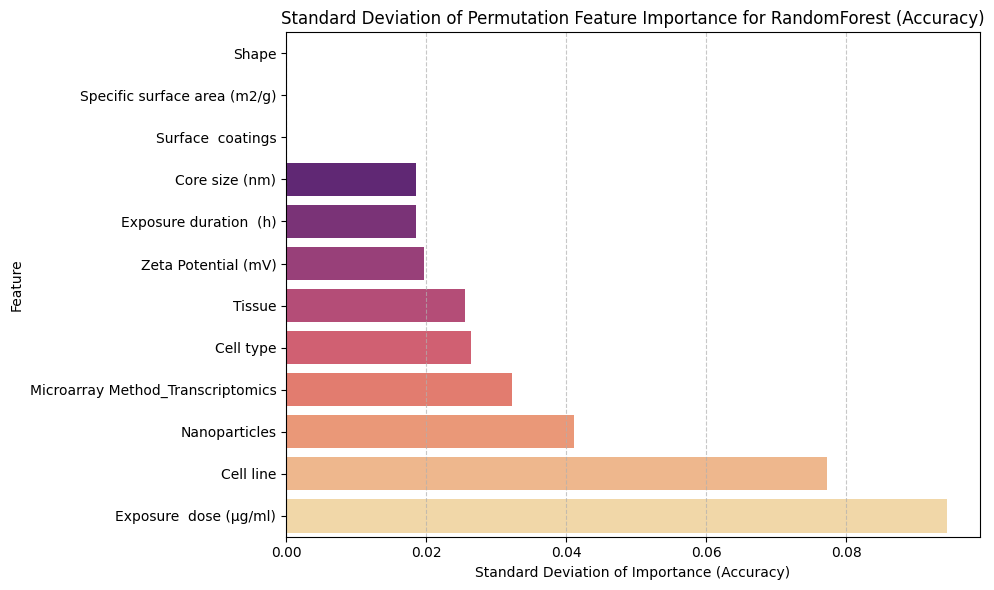

In [213]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Filter for RandomForest and accuracy metric (using the previously filtered rf_pfi_accuracy)

# Sort by standard deviation for visualization (or keep sorted by mean for consistency)
rf_pfi_accuracy_sorted_std = rf_pfi_accuracy.sort_values(by='std', ascending=True)

plt.figure(figsize=(10, 6))
sns.barplot(
    x='std',
    y='Feature',
    data=rf_pfi_accuracy_sorted_std,
    palette='magma',
    hue='Feature',
    legend=False
)
plt.xlabel('Standard Deviation of Importance (Accuracy)')
plt.ylabel('Feature')
plt.title('Standard Deviation of Permutation Feature Importance for RandomForest (Accuracy)')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [214]:
import pandas as pd

for result_entry in pfi_ncv_results:
    print(f"\n--- Classifier: {result_entry['Classifier']}, Scoring: {result_entry['Scoring_Metric']}, Fold: {result_entry['Fold']} ---")
    print(f"  Baseline Score: {result_entry['Baseline_Score']:.4f}")
    # Convert the list of dicts back to a DataFrame for better display
    if result_entry['PFI_Results']:
        display(pd.DataFrame(result_entry['PFI_Results']))
    else:
        print("  No PFI results for this fold (possibly due to error).")


--- Classifier: RandomForest, Scoring: accuracy, Fold: 1 ---
  Baseline Score: 0.9412


,Feature,Importance
0,Exposure dose (μg/ml),0.294118
1,Cell line,0.176471
2,Nanoparticles,0.000000
3,Core size (nm),0.000000
4,Surface coatings,0.000000
5,Shape,0.000000
6,Specific surface area (m2/g),0.000000
7,Zeta Potential (mV),0.000000
8,Exposure duration (h),0.000000
9,Tissue,0.000000



--- Classifier: RandomForest, Scoring: roc_auc, Fold: 1 ---
  Baseline Score: 0.9500


,Feature,Importance
0,Exposure dose (μg/ml),0.358333
1,Surface coatings,0.033333
2,Cell line,0.016667
3,Nanoparticles,0.016667
4,Cell type,0.000000
5,Tissue,0.000000
6,Specific surface area (m2/g),0.000000
7,Zeta Potential (mV),0.000000
8,Core size (nm),-0.016667
9,Shape,-0.033333



--- Classifier: RandomForest, Scoring: accuracy, Fold: 2 ---
  Baseline Score: 1.0000


,Feature,Importance
0,Cell line,0.294118
1,Exposure dose (μg/ml),0.176471
2,Nanoparticles,0.058824
3,Core size (nm),0.058824
4,Microarray Method_Transcriptomics,0.058824
5,Exposure duration (h),0.058824
6,Surface coatings,0.000000
7,Shape,0.000000
8,Zeta Potential (mV),0.000000
9,Specific surface area (m2/g),0.000000


... (190 outputs left out)


--- Classifier: ANN, Scoring: accuracy, Fold: 10 ---
  Baseline Score: 1.0000


,Feature,Importance
0,Microarray Method_Transcriptomics,0.3750
1,Cell line,0.3750
2,Zeta Potential (mV),0.3125
3,Exposure dose (μg/ml),0.2500
4,Tissue,0.1875
5,Cell type,0.1250
6,Nanoparticles,0.1250
7,Shape,0.0625
8,Surface coatings,0.0000
9,Core size (nm),0.0000



--- Classifier: ANN, Scoring: roc_auc, Fold: 10 ---
  Baseline Score: 1.0000


,Feature,Importance
0,Microarray Method_Transcriptomics,0.145455
1,Zeta Potential (mV),0.145455
2,Exposure dose (μg/ml),0.090909
3,Cell line,0.090909
4,Nanoparticles,0.018182
5,Surface coatings,0.000000
6,Core size (nm),0.000000
7,Shape,0.000000
8,Exposure duration (h),0.000000
9,Specific surface area (m2/g),0.000000


In [215]:
import pandas as pd

# Load the aggregated PFI results
aggregated_pfi_ncv = pd.read_excel(
    'pfi_results_ncv_best_models.xlsx',
    sheet_name='Aggregated_PFI_NCV'
)

# Filter for the best model based on accuracy (RandomForest) and 'accuracy' scoring metric only
filtered_pfi_accuracy_only = aggregated_pfi_ncv[
    (aggregated_pfi_ncv['Classifier'] == 'RandomForest') &
    (aggregated_pfi_ncv['Scoring_Metric'] == 'accuracy')
]

# Calculate the 'permutation combination score' by taking the mean importance for each feature
permutation_combination_score_accuracy = filtered_pfi_accuracy_only.groupby('Feature')['mean'].mean().sort_values(ascending=False)

print("\n--- Permutation Combination Score (RandomForest, Accuracy Metric Only) ---")
display(permutation_combination_score_accuracy.to_frame(name='Combined_Mean_Importance_Accuracy'))

# Save the permutation combination score to an Excel file
output_excel_file_combined_pfi_accuracy = "permutation_combination_score_randomforest_accuracy_only.xlsx"
permutation_combination_score_accuracy.to_frame(name='Combined_Mean_Importance_Accuracy').to_excel(
    output_excel_file_combined_pfi_accuracy,
    index=True # Keep feature names as index
)

print(f"\nPermutation Combination Scores saved to '{output_excel_file_combined_pfi_accuracy}'.")


--- Permutation Combination Score (RandomForest, Accuracy Metric Only) ---


,Combined_Mean_Importance_Accuracy
Feature,
Exposure dose (μg/ml),0.175368
Cell line,0.169485
Microarray Method_Transcriptomics,0.030515
Nanoparticles,0.023529
Cell type,0.012500
Tissue,0.012132
Zeta Potential (mV),0.006250
Core size (nm),0.005882
Exposure duration (h),0.005882



Permutation Combination Scores saved to 'permutation_combination_score_randomforest_accuracy_only.xlsx'.


In [216]:
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance

# -----------------------------------------------------------------------------
# Function to calculate the normalized PFI for a single model combination
# -----------------------------------------------------------------------------
def compute_pfi_normalized(model, X_test, y_test, combination_name, n_repeats=10):
    """
    model            : trained pipeline (imputer + classifier)
    X_test, y_test   : test data setelah preprocessing pipeline
    combination_name : "Imputer + Classifier"
    n_repeats        : jumlah permutasi (default 10)
    """

    # === 1. Calculate baseline accuracy ===
    baseline_acc = model.score(X_test, y_test)

    # === 2. Calculate PFI using sklearn ===
    pfi = permutation_importance(
        model,
        X_test,
        y_test,
        n_repeats=n_repeats,
        random_state=42
    )

    importances = pfi.importances_mean   # importance per fitur
    num_features = len(importances)      # jumlah fitur final

    # === 3. Calculate PFI (Raw) ===
    PFI_raw = np.sum(importances)  # the amount of change resulting from the permutation of all features

    # === 4. Calculate Normalized PFI ===
    # PFI_norm = average PFI per feature, calibrated to 0–1
    PFI_norm = PFI_raw/ num_features

    # === 5. Save the result to the dictionary ===
    result = {
        "Combination": combination_name,
        "BaselineAccuracy": baseline_acc,
        "NumFeatures": num_features,
        "PFI_List": importances.tolist(),
        "PFI_Raw": PFI_raw,
        "PFI_Normalized": PFI_norm
    }

    return result

# -------------------------------------------------------------------
# EXAMPLE OF USE FOR 1 MODEL (Loop will be the same for 5 combinations)
# -------------------------------------------------------------------
pfi_results = []

# Assuming the context for these models is 'CCA' (Complete Case Analysis)
imp_name = "CCA"

for clf_name, model_pipeline in best_trained_models.items():   # Use best_trained_models from previous cells
    combination = f"{imp_name} + {clf_name}"
    print(f"Calculating Normalized PFI for {combination} ...")

    result = compute_pfi_normalized(
        model=model_pipeline,
        X_test=X_test,     # Use raw X_test, pipeline will transform automatically
        y_test=y_test,
        combination_name=combination
    )

    pfi_results.append(result)

# Conversion to DataFrame
df_pfi = pd.DataFrame(pfi_results)

print("\n=== PFI NORMALIZED RESULTS ===")
print(df_pfi)

# Save to Excel
df_pfi.to_excel("PFI_Normalized_Results-cca.xlsx", index=False)
print("\nPFI Normalized has been saved to PFI_Normalized_Results-cca.xlsx")

Calculating Normalized PFI for CCA + RandomForest ...
Calculating Normalized PFI for CCA + DecisionTree ...
Calculating Normalized PFI for CCA + SVM ...
Calculating Normalized PFI for CCA + NaiveBayes ...
Calculating Normalized PFI for CCA + ANN ...

=== PFI NORMALIZED RESULTS ===
          Combination  BaselineAccuracy  NumFeatures  \
0  CCA + RandomForest          0.928571           12   
1  CCA + DecisionTree          0.857143           12   
2           CCA + SVM          1.000000           12   
3    CCA + NaiveBayes          0.785714           12   
4           CCA + ANN          0.928571           12   

                                            PFI_List   PFI_Raw  PFI_Normalized  
0  [0.014285714285714323, 0.0, 0.0, 0.0, -0.01428...  0.292857        0.024405  
1  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1357142857142...  0.235714        0.019643  
2  [0.1642857142857143, 0.0357142857142857, 0.0, ...  1.007143        0.083929  
3  [0.1357142857142857, 0.0, 0.0, 0.0, 0.0, 0.0, ...  0.2

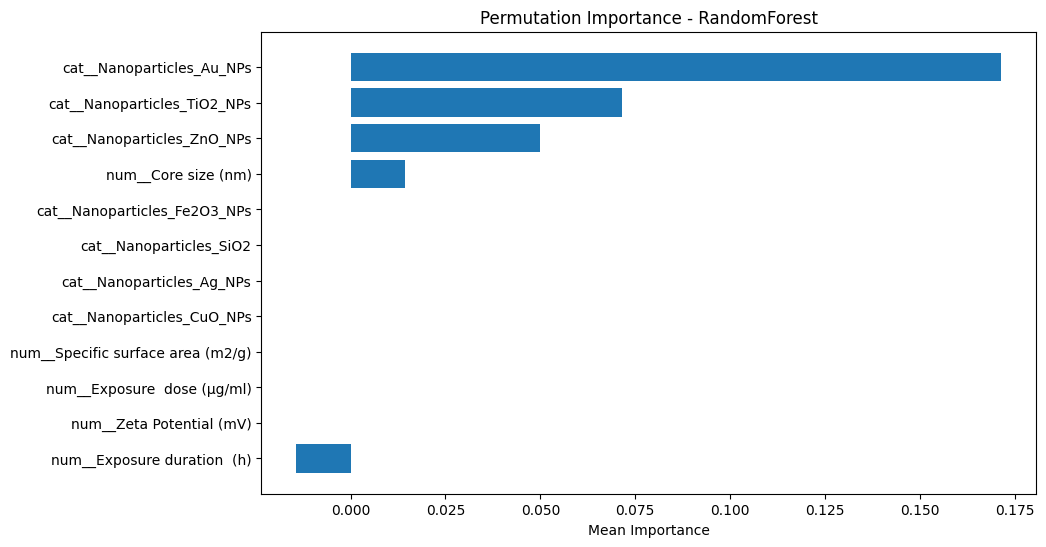

In [217]:
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

# Choose the model from best_trained_models you want to visualize
# For example, using the 'RandomForest' model:
selected_model_pipeline = best_trained_models['RandomForest']

r = permutation_importance(selected_model_pipeline, X_test, y_test, n_repeats=10, random_state=42)

sorted_idx = r.importances_mean.argsort()
features = selected_model_pipeline.named_steps['preprocess'].get_feature_names_out()

plt.figure(figsize=(10, 6))
plt.barh(features[sorted_idx], r.importances_mean[sorted_idx])
plt.xlabel("Mean Importance")
plt.title(f"Permutation Importance - RandomForest")
plt.show()

In [218]:
df_permutation_importances = aggregated_pfi_ncv.copy()
df_permutation_importances['Imputation'] = 'CCA' # Add the imputation method explicitly
df_permutation_importances['Mean_Importance'] = df_permutation_importances['mean'] # Rename 'mean' to 'Mean_Importance'

# Calculate the sum of absolute Mean_Importance for each model combination
df_permutation_importances['Absolute_Mean_Importance'] = df_permutation_importances['Mean_Importance'].abs()
sum_abs_importance_per_model = df_permutation_importances.groupby(['Imputation', 'Classifier', 'Scoring_Metric'])['Absolute_Mean_Importance'].transform('sum')

# Normalize Mean_Importance per model (divide by the sum of absolute importances for that model)
df_permutation_importances['Normalized_Mean_Importance'] = df_permutation_importances['Mean_Importance'] / sum_abs_importance_per_model

print("DataFrame with Normalized_Mean_Importance per Model:")
display(df_permutation_importances.head(15)) # Display first 15 rows to show a few models

DataFrame with Normalized_Mean_Importance per Model:


,Classifier,Scoring_Metric,Feature,mean,std,Imputation,Mean_Importance,Absolute_Mean_Importance,Normalized_Mean_Importance
0,ANN,accuracy,Cell line,0.250735,0.063603,CCA,0.250735,0.250735,0.152881
1,ANN,accuracy,Cell type,0.169853,0.078523,CCA,0.169853,0.169853,0.103564
2,ANN,accuracy,Core size (nm),-0.012132,0.025592,CCA,-0.012132,0.012132,-0.007397
3,ANN,accuracy,Exposure dose (μg/ml),0.231618,0.094195,CCA,0.231618,0.231618,0.141224
4,ANN,accuracy,Exposure duration (h),-0.011397,0.047032,CCA,-0.011397,0.011397,-0.006949
5,ANN,accuracy,Microarray Method_Transcriptomics,0.226838,0.075585,CCA,0.226838,0.226838,0.138310
6,ANN,accuracy,Nanoparticles,0.183456,0.052294,CCA,0.183456,0.183456,0.111858
7,ANN,accuracy,Shape,0.079044,0.049454,CCA,0.079044,0.079044,0.048195
8,ANN,accuracy,Specific surface area (m2/g),0.085294,0.077328,CCA,0.085294,0.085294,0.052006
9,ANN,accuracy,Surface coatings,0.120956,0.107808,CCA,0.120956,0.120956,0.073750


In [219]:
# Calculate meanmodel(Norm(PFIimp,model,j))
# Group by 'Imputation' and 'Feature', then average 'Normalized_Mean_Importance' across classifiers
mean_norm_importance_per_imputation_feature = df_permutation_importances.groupby(['Imputation', 'Feature'])['Normalized_Mean_Importance'].mean().reset_index()

print("Average Normalized_Mean_Importance per Imputation and Feature (meanmodel):")
display(mean_norm_importance_per_imputation_feature.head())

Average Normalized_Mean_Importance per Imputation and Feature (meanmodel):


,Imputation,Feature,Normalized_Mean_Importance
0,CCA,Cell line,0.338982
1,CCA,Cell type,0.013235
2,CCA,Core size (nm),-0.002812
3,CCA,Exposure dose (μg/ml),0.336341
4,CCA,Exposure duration (h),-0.003114


In [220]:
import pandas as pd
import numpy as np
import os

# 1. Determine the potential file path for the PFI output
possible_paths = [
    'pfi_results_ncv_best_models.xlsx'
]

# Ensure that the 'aggregated_pfi_ncv' data is available in memory
if 'aggregated_pfi_ncv' not in globals():
    loaded = False
    for path in possible_paths:
        if os.path.exists(path):
            print(f"Memuat data aggregated PFI dari file '{path}'...")
            aggregated_pfi_ncv = pd.read_excel(path, sheet_name='Aggregated_PFI_NCV')
            loaded = True
            break

    if not loaded:
        if 'detailed_pfi_ncv_df' in globals():
            print("Dynamically create aggregated_pfi_ncv data from detailed_pfi_ncv_df in memory...")
            aggregated_pfi_ncv = detailed_pfi_ncv_df.groupby(['Classifier', 'Scoring_Metric', 'Feature'])['Importance'].agg(['mean', 'std']).reset_index()
        else:
            print("WARNING: NCV variables and PFI files were not found in the current runtime session.")
            print("Please re-run the cell first to generate the NCV PF data.")
            raise FileNotFoundError("The file 'pfi_results_ncv_best_models.xlsx' was not found. Please run it again")

# Retrieve the PFI data resulting from the aggregated 10-fold CV for the RandomForest model (Accuracy)
df_rf_pfi = aggregated_pfi_ncv[
    (aggregated_pfi_ncv['Classifier'] == 'RandomForest') &
    (aggregated_pfi_ncv['Scoring_Metric'] == 'accuracy')
].copy()

# Rename the columns to make them easier to understand
df_rf_pfi = df_rf_pfi.rename(columns={'mean': 'PFI_Mean', 'std': 'PFI_Std'})

# 2. Calculate the total PFI sum across all features (P)
total_pfi = df_rf_pfi['PFI_Mean'].sum()

# 3. Calculate Normalized PFI using the proportional contribution formula
#PFI_norm_j = PFI_mean_j / total_pfi
df_rf_pfi['PFI_Normalized_Proportional'] = df_rf_pfi['PFI_Mean'] / total_pfi

# 4. Sort by contribution value, from highest to lowest
df_rf_pfi_sorted = df_rf_pfi.sort_values(by='PFI_Normalized_Proportional', ascending=False).reset_index(drop=True)

# 5. Add a contribution percentage column to make it easier to read
df_rf_pfi_sorted['Percentage_Contribution'] = df_rf_pfi_sorted['PFI_Normalized_Proportional'].apply(lambda x: f"{x:.2%}")

print(f"Total Number of PFIs (Denominator): {total_pfi:.6f}")
print("\n=== PFI NORMALIZATION RESULTS WITH PROPORTIONAL CONTRIBUTION (RANDOM FOREST) ===")
display(df_rf_pfi_sorted[['Feature', 'PFI_Mean', 'PFI_Normalized_Proportional', 'Percentage_Contribution']])

# 6. Save the calculation results to an Excel file
output_file_name = "PFI_Normalized_Proportional_Contribution.xlsx"
df_rf_pfi_sorted[['Feature', 'PFI_Mean', 'PFI_Normalized_Proportional', 'Percentage_Contribution']].to_excel(output_file_name, index=False)
print(f"\nThe calculation results have been successfully saved to a file '{output_file_name}'")

Total Number of PFIs (Denominator): 0.441544

=== PFI NORMALIZATION RESULTS WITH PROPORTIONAL CONTRIBUTION (RANDOM FOREST) ===


,Feature,PFI_Mean,PFI_Normalized_Proportional,Percentage_Contribution
0,Exposure dose (μg/ml),0.175368,0.397169,39.72%
1,Cell line,0.169485,0.383847,38.38%
2,Microarray Method_Transcriptomics,0.030515,0.069109,6.91%
3,Nanoparticles,0.023529,0.053289,5.33%
4,Cell type,0.012500,0.028310,2.83%
5,Tissue,0.012132,0.027477,2.75%
6,Zeta Potential (mV),0.006250,0.014155,1.42%
7,Core size (nm),0.005882,0.013322,1.33%
8,Exposure duration (h),0.005882,0.013322,1.33%
9,Shape,0.000000,0.000000,0.00%



The calculation results have been successfully saved to a file 'PFI_Normalized_Proportional_Contribution.xlsx'


In [221]:
display(aggregated_pfi_ncv)

,Classifier,Scoring_Metric,Feature,mean,std
0,ANN,accuracy,Cell line,0.250735,0.063603
1,ANN,accuracy,Cell type,0.169853,0.078523
2,ANN,accuracy,Core size (nm),-0.012132,0.025592
3,ANN,accuracy,Exposure dose (μg/ml),0.231618,0.094195
4,ANN,accuracy,Exposure duration (h),-0.011397,0.047032
...,...,...,...,...,...
115,SVM,roc_auc,Shape,-0.005303,0.022668
116,SVM,roc_auc,Specific surface area (m2/g),-0.018939,0.041249
117,SVM,roc_auc,Surface coatings,-0.001667,0.017934
118,SVM,roc_auc,Tissue,0.004848,0.041166


In [222]:
import pandas as pd
import numpy as np

# Filter aggregated_pfi_ncv untuk model RandomForest dan metrik 'accuracy'
df_rf_pfi_accuracy = aggregated_pfi_ncv[
    (aggregated_pfi_ncv['Classifier'] == 'RandomForest') &
    (aggregated_pfi_ncv['Scoring_Metric'] == 'accuracy')
].copy()

# Renaming columns to make them more informative and easier to read
df_rf_pfi_accuracy = df_rf_pfi_accuracy.rename(columns={
    'Feature': 'Original_Feature',
    'mean': 'Mean_PFI_Accuracy',
    'std': 'Std_Dev_PFI_Accuracy'
})

# Sorting from the highest to the lowest Mean_PFI_Accuracy value
df_rf_pfi_sorted = df_rf_pfi_accuracy.sort_values(by='Mean_PFI_Accuracy', ascending=False).reset_index(drop=True)

# Selecting the columns required for the output
final_pfi_table = df_rf_pfi_sorted[['Original_Feature', 'Mean_PFI_Accuracy', 'Std_Dev_PFI_Accuracy']]

# Displaying the table of sorted results
print("=== 10-FOLD NESTED CV PERMUTATION FEATURE IMPORTANCE (PFI) TABLE: RANDOM FOREST (METRIC ACCURACY SEQUENCE) ===")
display(final_pfi_table)

# Save results into an Excel file (.xlsx)
output_excel_file = "pfi_nested_cv_randomforest_accuracy_sorted.xlsx"
final_pfi_table.to_excel(output_excel_file, index=False)
print(f"\nThe PFI RandomForest ranking results have been successfully saved to a file: '{output_excel_file}'")

=== 10-FOLD NESTED CV PERMUTATION FEATURE IMPORTANCE (PFI) TABLE: RANDOM FOREST (METRIC ACCURACY SEQUENCE) ===


,Original_Feature,Mean_PFI_Accuracy,Std_Dev_PFI_Accuracy
0,Exposure dose (μg/ml),0.175368,0.094340
1,Cell line,0.169485,0.077185
2,Microarray Method_Transcriptomics,0.030515,0.032193
3,Nanoparticles,0.023529,0.041130
4,Cell type,0.012500,0.026352
5,Tissue,0.012132,0.025592
6,Zeta Potential (mV),0.006250,0.019764
7,Core size (nm),0.005882,0.018602
8,Exposure duration (h),0.005882,0.018602
9,Shape,0.000000,0.000000



The PFI RandomForest ranking results have been successfully saved to a file: 'pfi_nested_cv_randomforest_accuracy_sorted.xlsx'


In [223]:
import ast

best_classifier_name = best_cv_accuracy_model_name

# Get the original unfitted model and its parameter grid
base_model, param_grid = models_param[best_classifier_name]

numeric_transformer = SkPipeline(steps=[("scaler", StandardScaler())])
categorical_transformer = SkPipeline(steps=[("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder='passthrough'
)

# Create the pipeline with the base model
pipeline_for_best_model = SkPipeline(steps=[
    ("preprocess", preprocessor),
    ("clf", base_model)
])

# Retrieve the best parameters found for this model during the evaluation phase
# Find the row for the best classifier:
best_model_row = test_results_df[test_results_df['Classifier'] == best_classifier_name].iloc[0]
best_params_str = best_model_row['Best_Params']

# Convert the string representation of best_params back to a dictionary
# Using ast.literal_eval for safe evaluation of string containing Python literal structure
best_params_for_best_model = ast.literal_eval(best_params_str)

# Set these best parameters to the newly created pipeline instance
best_model = pipeline_for_best_model.set_params(**best_params_for_best_model)

best_model.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['Core size (nm)',
                                                   'Zeta Potential (mV)',
                                                   'Specific surface area '
                                                   '(m2/g)',
                                                   'Exposure  dose (μg/ml)',
                                                   'Exposure duration  (h)']),
                                                 ('cat',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['Nanoparticles', 'Shape',
                                                   'Surface  coatings',
                                                   'Tissue', 'Cell type',
                                                   'Cell line',
                                                   'Microarray '
                                                   'Method_Transcriptomics'])])),
                ('clf',
                 RandomForestClassifier(min_samples_split=5, n_estimators=400,
                                        n_jobs=-1, random_state=42))])

In [224]:
# Predict on the test data using the best_model
y_pred_test_final = best_model.predict(X_test)

# Get probabilities for ROC AUC if the model supports it
y_proba_test_final = None
if hasattr(best_model.named_steps['clf'], 'predict_proba'):
    y_proba_test_final = best_model.predict_proba(X_test)

# Compute final evaluation metrics
final_model_metrics = compute_metrics(y_test, y_pred_test_final, y_proba_test_final)

# Convert results to DataFrame for display
final_model_metrics_df = pd.DataFrame([final_model_metrics])
final_model_metrics_df.insert(0, 'Classifier', best_classifier_name)
final_model_metrics_df.insert(1, 'Imputation', 'CCA') # Assuming 'CCA' from context

# Format relevant columns as percentages
percentage_cols_final = [
    "Accuracy", "Precision", "Sensitivity", "F1", "Specificity",
    "AUC", "Error_Rate", "FPR", "FNR"
]

for col in percentage_cols_final:
    if col in final_model_metrics_df.columns:
        final_model_metrics_df[col] = pd.to_numeric(final_model_metrics_df[col], errors='coerce')
        final_model_metrics_df[col] = final_model_metrics_df[col].apply(lambda x: f"{x:.2%}" if pd.notna(x) else x)

print(f"\nFinal Performance of {best_classifier_name} (CCA) on Test Data:")
display(final_model_metrics_df)

# Save the final evaluation results to an Excel file
output_excel_file_final = "final_best_model_performance.xlsx"
final_model_metrics_df.to_excel(output_excel_file_final, index=False)
print(f"\nFinal model performance results saved to '{output_excel_file_final}'.")


Final Performance of RandomForest (CCA) on Test Data:


,Classifier,Imputation,Accuracy,Precision,Sensitivity,F1,Specificity,AUC,Error_Rate,FPR,FNR
0,RandomForest,CCA,92.86%,100.00%,75.00%,85.71%,100.00%,100.00%,7.14%,0.00%,25.00%



Final model performance results saved to 'final_best_model_performance.xlsx'.


In [225]:
import pandas as pd
import numpy as np

# Load detailed 10-fold CV results
cv_results_raw = pd.read_excel('model_evaluation_results_10fold_cv_per_fold_cca.xlsx')

# Helper function to convert percentage strings to float
def percentage_to_float_col(series):
    return series.astype(str).str.replace('%', '', regex=False).astype(float) / 100

# Clean target metrics columns to float for calculation
cv_results_clean = cv_results_raw.copy()
target_metrics = ['Accuracy', 'F1', 'Precision', 'Specificity', 'Sensitivity', 'AUC', 'Error_Rate']

for col in target_metrics:
    if col in cv_results_clean.columns:
        cv_results_clean[col] = percentage_to_float_col(cv_results_clean[col])

# Calculate mean and standard deviation
mean_metrics = cv_results_clean.groupby('Classifier')[target_metrics].mean()
std_metrics = cv_results_clean.groupby('Classifier')[target_metrics].std()

# Combine mean and std dev into a single readable summary table
summary_results = {}
for col in target_metrics:
    summary_results[col] = mean_metrics[col].apply(lambda x: f"{x:.2%}") + " ± " + std_metrics[col].apply(lambda x: f"{x:.2%}")

df_summary_ncv = pd.DataFrame(summary_results)

print("=== SUMMARY OF MODEL PERFORMANCE METRICS (10-FOLD NESTED CV) ===")
display(df_summary_ncv)


=== SUMMARY OF MODEL PERFORMANCE METRICS (10-FOLD NESTED CV) ===


,Accuracy,F1,Precision,Specificity,Sensitivity,AUC,Error_Rate
Classifier,,,,,,,
ANN,93.97% ± 4.91%,89.80% ± 9.02%,93.24% ± 8.84%,96.44% ± 4.60%,88.67% ± 15.73%,93.70% ± 6.97%,6.03% ± 4.91%
DecisionTree,92.06% ± 7.23%,84.72% ± 19.10%,93.00% ± 9.09%,96.44% ± 4.60%,82.67% ± 23.92%,92.80% ± 12.67%,7.94% ± 7.23%
NaiveBayes,74.52% ± 10.76%,70.88% ± 10.71%,57.28% ± 12.16%,65.23% ± 13.60%,94.33% ± 9.17%,79.41% ± 10.34%,25.48% ± 10.76%
RandomForest,94.52% ± 4.48%,91.31% ± 6.48%,95.48% ± 9.94%,97.27% ± 6.14%,88.67% ± 9.84%,97.47% ± 2.59%,5.48% ± 4.48%
SVM,92.06% ± 2.99%,86.86% ± 5.56%,91.33% ± 9.19%,95.53% ± 4.72%,84.67% ± 12.49%,92.36% ± 7.91%,7.94% ± 2.99%


In [226]:
import numpy as np
import pandas as pd
from statsmodels.stats.proportion import proportion_confint
from sklearn.utils import resample
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score

# 1. Define Ground Truth Data for Evaluation (using variables from memory)
N_test = len(y_test)
y_true_test = (y_test == POS_LABEL).astype(int).values
y_pred_test_val = (y_pred_test_final == POS_LABEL).astype(int)
y_proba_test_pos = y_proba_test_final[:, 1] if y_proba_test_final is not None else None

# Helper function for Wilson Score Interval
def get_wilson_ci(successes, trials):
    if trials > 0:
        return proportion_confint(successes, trials, alpha=0.05, method='wilson')
    return np.nan, np.nan

# =========================================================================
# PART A: Calculating Metrics Using the Wilson Score Interval (95% CI)
# =========================================================================

# 1. Accuracy
success_acc = np.sum(y_true_test == y_pred_test_val)
ci_acc_low, ci_acc_upp = get_wilson_ci(success_acc, N_test)

# 2. Precision
pos_pred = np.sum(y_pred_test_val == 1)
success_prec = np.sum((y_true_test == 1) & (y_pred_test_val == 1))
ci_prec_low, ci_prec_upp = get_wilson_ci(success_prec, pos_pred)

# 3. Sensitivity
pos_actual = np.sum(y_true_test == 1)
success_sens = np.sum((y_true_test == 1) & (y_pred_test_val == 1))
ci_sens_low, ci_sens_upp = get_wilson_ci(success_sens, pos_actual)

# 4. Specificity
neg_actual = np.sum(y_true_test == 0)
success_spec = np.sum((y_true_test == 0) & (y_pred_test_val == 0))
ci_spec_low, ci_spec_upp = get_wilson_ci(success_spec, neg_actual)

# 5. Error Rate
success_err = np.sum(y_true_test != y_pred_test_val)
ci_err_low, ci_err_upp = get_wilson_ci(success_err, N_test)

# Add to the temporary list
wilson_results = [
    {"Metric": "Accuracy", "Value": final_model_metrics["Accuracy"], "95% CI Lower": ci_acc_low, "95% CI Upper": ci_acc_upp, "Method": "Wilson Score"},
    {"Metric": "Precision", "Value": final_model_metrics["Precision"], "95% CI Lower": ci_prec_low, "95% CI Upper": ci_prec_upp, "Method": "Wilson Score"},
    {"Metric": "Sensitivity", "Value": final_model_metrics["Sensitivity"], "95% CI Lower": ci_sens_low, "95% CI Upper": ci_sens_upp, "Method": "Wilson Score"},
    {"Metric": "Specificity", "Value": final_model_metrics["Specificity"], "95% CI Lower": ci_spec_low, "95% CI Upper": ci_spec_upp, "Method": "Wilson Score"},
    {"Metric": "Error Rate", "Value": final_model_metrics["Error_Rate"], "95% CI Lower": ci_err_low, "95% CI Upper": ci_err_upp, "Method": "Wilson Score"}
]

# =========================================================================
# PART B: Calculating Metrics with 1000x Bootstrapping (95% CI)
# =========================================================================

N_bootstrap = 1000
boot_f1 = []
boot_auc = []

indices = np.arange(len(y_true_test))
np.random.seed(42)

for i in range(N_bootstrap):
    boot_idx = resample(indices, replace=True, n_samples=len(indices), random_state=42+i)
    y_t_boot = y_true_test[boot_idx]
    y_p_boot = y_pred_test_val[boot_idx]

    # F1-Score
    f1_b = f1_score(y_t_boot, y_p_boot, zero_division=0)
    boot_f1.append(f1_b)

    # AUC
    if y_proba_test_pos is not None:
        y_prob_boot = y_proba_test_pos[boot_idx]
        if len(np.unique(y_t_boot)) > 1:
            auc_b = roc_auc_score(y_t_boot, y_prob_boot)
        else:
            auc_b = np.nan
        boot_auc.append(auc_b)
    else:
        boot_auc.append(np.nan)

# Cleanse NaN values ​​for AUC percentile calculations
valid_f1 = [v for v in boot_f1 if pd.notna(v)]
valid_auc = [v for v in boot_auc if pd.notna(v)]

ci_f1_low, ci_f1_upp = np.percentile(valid_f1, 2.5), np.percentile(valid_f1, 97.5)
ci_auc_low, ci_auc_upp = np.percentile(valid_auc, 2.5) if len(valid_auc) > 0 else np.nan, np.percentile(valid_auc, 97.5) if len(valid_auc) > 0 else np.nan

bootstrap_results = [
    {"Metric": "F1-Score", "Value": final_model_metrics["F1"], "95% CI Lower": ci_f1_low, "95% CI Upper": ci_f1_upp, "Method": "Bootstrap (1000x)"},
    {"Metric": "AUC", "Value": final_model_metrics["AUC"], "95% CI Lower": ci_auc_low, "95% CI Upper": ci_auc_upp, "Method": "Bootstrap (1000x)"}
]

# =========================================================================
# PART C: Combining and Displaying Analysis Results
# =========================================================================

combined_df = pd.DataFrame(wilson_results + bootstrap_results)

# Display format to percentage for neat reading
display_df = combined_df.copy()
for col in ["Value", "95% CI Lower", "95% CI Upper"]:
    display_df[col] = display_df[col].apply(lambda x: f"{x:.2%}" if pd.notna(x) else "N/A")

print("=== EVALUATION RESULTS: 95% CONFIDENCE INTERVAL (GENERATED FROM SCRATCH) ===")
display(display_df[["Metric", "Value", "95% CI Lower", "95% CI Upper", "Method"]])

# Saving the final result
combined_df.to_excel("comprehensive_confidence_interval_summary.xlsx", index=False)
print("\nThe comprehensive analysis results were successfully saved to 'comprehensive_confidence_interval_summary.xlsx'")

=== EVALUATION RESULTS: 95% CONFIDENCE INTERVAL (GENERATED FROM SCRATCH) ===


,Metric,Value,95% CI Lower,95% CI Upper,Method
0,Accuracy,92.86%,68.53%,98.73%,Wilson Score
1,Precision,100.00%,43.85%,100.00%,Wilson Score
2,Sensitivity,75.00%,30.06%,95.44%,Wilson Score
3,Specificity,100.00%,72.25%,100.00%,Wilson Score
4,Error Rate,7.14%,1.27%,31.47%,Wilson Score
5,F1-Score,85.71%,0.00%,100.00%,Bootstrap (1000x)
6,AUC,100.00%,100.00%,100.00%,Bootstrap (1000x)



The comprehensive analysis results were successfully saved to 'comprehensive_confidence_interval_summary.xlsx'



=== Confusion Matrix for Final Model ===


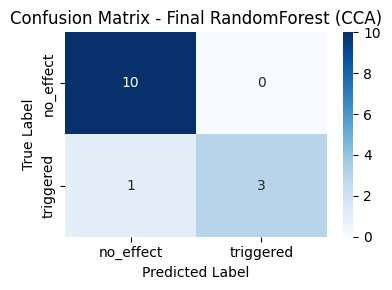

In [228]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print(f"\n=========================================")
print(f"=== Confusion Matrix for Final Model ===")
print(f"=========================================")

# Predict on the test data using the best_model
y_pred_test_final_cm = best_model.predict(X_test)

# Get unique classes, ensuring consistent order for confusion matrix
classes = sorted(y_test.unique())

# Calculate Confusion Matrix
cm = confusion_matrix(y_test, y_pred_test_final_cm, labels=classes)

# Display Confusion Matrix using seaborn and matplotlib
plt.figure(figsize=(4, 3))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=classes,
    yticklabels=classes
)
plt.title(f'Confusion Matrix - Final {best_classifier_name} (CCA)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

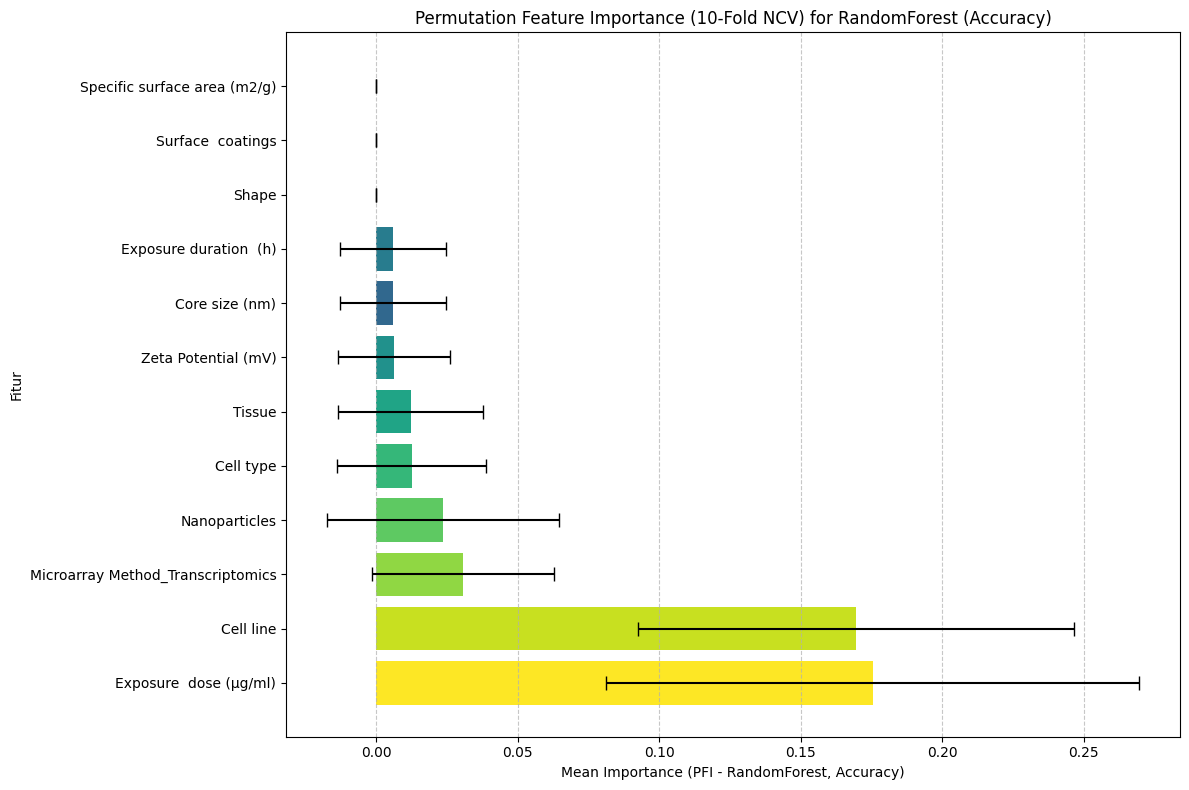

In [229]:
import matplotlib.pyplot as plt
import pandas as pd

# Filter aggregated_pfi_ncv for the best model and the 'accuracy' metric
filtered_pfi_accuracy = aggregated_pfi_ncv[
    (aggregated_pfi_ncv['Classifier'] == best_cv_accuracy_model_name) &
    (aggregated_pfi_ncv['Scoring_Metric'] == 'accuracy')
].copy()

# Sort by average Importance for better visualization
filtered_pfi_accuracy = filtered_pfi_accuracy.sort_values(by='mean', ascending=False)

# Set the 'Feature' column as an ordered categorical type to preserve the order in the plot
filtered_pfi_accuracy['Feature'] = pd.Categorical(
    filtered_pfi_accuracy['Feature'],
    categories=filtered_pfi_accuracy['Feature'].tolist(),
    ordered=True
)

plt.figure(figsize=(12, 8))

# Using plt.barh for better control over error bars
plt.barh(
    y=filtered_pfi_accuracy['Feature'],
    width=filtered_pfi_accuracy['mean'],
    xerr=filtered_pfi_accuracy['std'], # Melewatkan standar deviasi sebagai error bars
    color=plt.cm.viridis(filtered_pfi_accuracy['mean'].rank(method='first')/len(filtered_pfi_accuracy)), # Memberi warna berdasarkan peringkat kepentingan
    capsize=5 # Menambahkan cap ke error bars
)

plt.xlabel(f'Mean Importance (PFI - {best_cv_accuracy_model_name}, Accuracy)')
plt.ylabel('Fitur')
plt.title(f'Permutation Feature Importance (10-Fold NCV) for {best_cv_accuracy_model_name} (Accuracy)')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

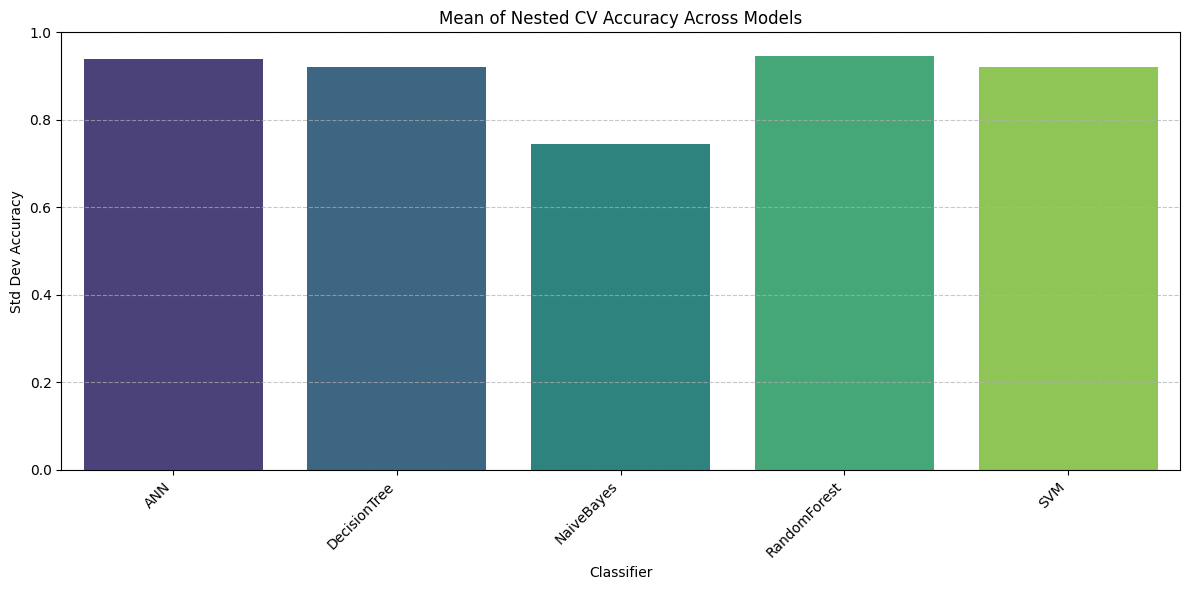

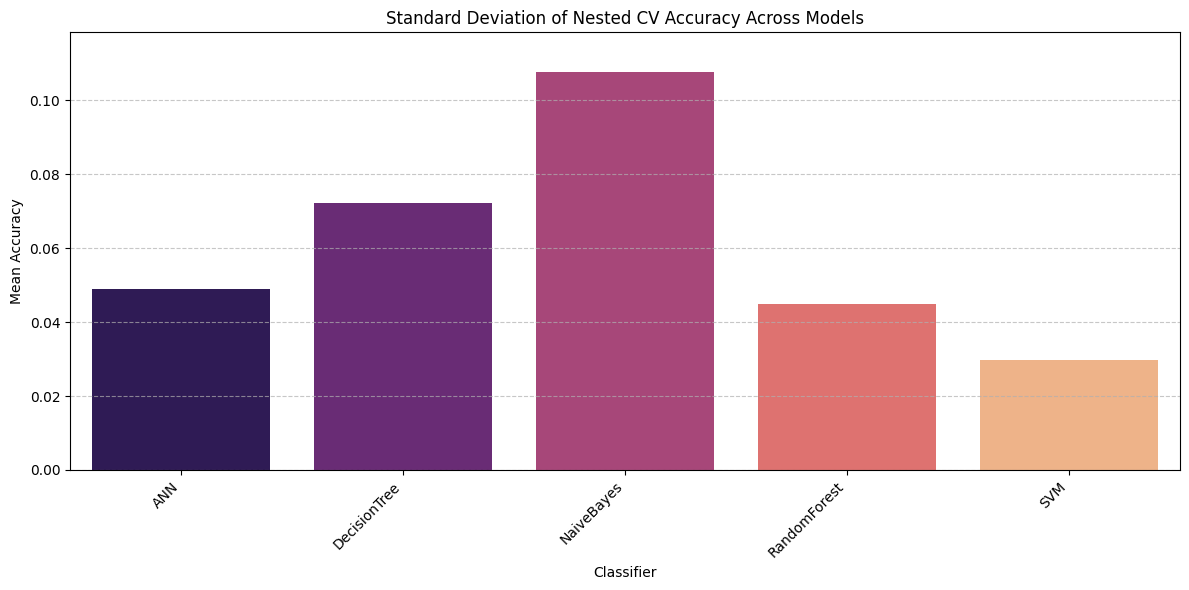

In [230]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

metrics_to_plot = ['Accuracy']

# Combine the mean and std into a single DataFrame to facilitate plotting
plot_df = mean_metrics_cv[metrics_to_plot].stack().reset_index()
plot_df.columns = ['Classifier', 'Metric', 'Mean_Value']

# Add the standard deviation value
std_values = std_metrics_cv[metrics_to_plot].stack().reset_index()
std_values.columns = ['Classifier', 'Metric', 'Std_Value']

plot_df = pd.merge(plot_df, std_values, on=['Classifier', 'Metric'])

# --- Plot 1: Mean of Accuracy ---
plt.figure(figsize=(12, 6))
sns.barplot(
    x='Classifier',
    y='Mean_Value',
    data=plot_df,
    palette='viridis',
    hue='Classifier',
    legend=False
)
plt.title('Mean of Nested CV Accuracy Across Models')
plt.xlabel('Classifier')
plt.ylabel('Std Dev Accuracy')
plt.ylim(0, 1)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# --- Plot 2: Standard Deviation of Accuracy ---
plt.figure(figsize=(12, 6))
sns.barplot(
    x='Classifier',
    y='Std_Value',
    data=plot_df,
    palette='magma',
    hue='Classifier',
    legend=False
)
plt.title('Standard Deviation of Nested CV Accuracy Across Models')
plt.xlabel('Classifier')
plt.ylabel('Mean Accuracy')
plt.ylim(0, plot_df['Std_Value'].max() * 1.1)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [231]:
import pandas as pd
import numpy as np

# 1. Load training data and details per CV fold
df_train = pd.read_excel('model_training_evaluation_results_no_imputation_cca.xlsx')
df_cv_folds = pd.read_excel('model_evaluation_results_10fold_cv_per_fold_cca.xlsx')

# 2. Define target metrics
metrics = ['Accuracy', 'Precision', 'Sensitivity', 'F1', 'Specificity', 'AUC']

# 3. Helper function to clean a percentage value into a float
def clean_pct_to_float(df, cols):
    df_cleaned = df.copy()
    for col in cols:
        if col in df_cleaned.columns:
            df_cleaned[col] = df_cleaned[col].astype(str).str.replace('%', '', regex=False).astype(float) / 100.0
    return df_cleaned

df_train_num = clean_pct_to_float(df_train, metrics)
df_cv_folds_num = clean_pct_to_float(df_cv_folds, metrics)

# 4. Calculate the overfitting gap per fold (G_i,c,k = M_train - M_val,fold_k)
fold_gaps = []
for _, train_row in df_train_num.iterrows():
    clf = train_row['Classifier']
    clf_folds = df_cv_folds_num[df_cv_folds_num['Classifier'] == clf]

    for _, fold_row in clf_folds.iterrows():
        fold_num = fold_row['Fold']
        gap_entry = {'Classifier': clf, 'Fold': fold_num}
        for m in metrics:
            m_train = train_row[m]
            m_val_fold = fold_row[m]
            gap_entry[f'{m}_Gap'] = m_train - m_val_fold
        fold_gaps.append(gap_entry)

df_fold_gaps = pd.DataFrame(fold_gaps)

# 5. Calculate the mean overfitting gap and its standard deviation for each classifier
summary_results = []
for clf in df_fold_gaps['Classifier'].unique():
    clf_data = df_fold_gaps[df_fold_gaps['Classifier'] == clf]
    summary_entry = {'Classifier': clf}
    for m in metrics:
        mean_gap = clf_data[f'{m}_Gap'].mean()
        std_gap = clf_data[f'{m}_Gap'].std()
        summary_entry[f'{m}_Mean_Gap'] = mean_gap
        summary_entry[f'{m}_Std_Gap'] = std_gap
    summary_results.append(summary_entry)

df_gap_summary = pd.DataFrame(summary_results)

# 6. Format the display as a percentage
df_display = df_gap_summary.copy()
for m in metrics:
    df_display[f'{m}_Mean_Gap'] = df_display[f'{m}_Mean_Gap'].apply(lambda x: f" {x:.2%}" if pd.notna(x) else np.nan)
    df_display[f'{m}_Std_Gap'] = df_display[f'{m}_Std_Gap'].apply(lambda x: f"{x:.2%}" if pd.notna(x) else np.nan)

print("=== SUMMARY GAP OVERFITTING (MEAN & STD DEVIATION) PER CLASSIFIER ===")
display(df_display)

# Save the analysis results to an Excel file
df_gap_summary.to_excel('summary_gap_overfitting_ncv_cca.xlsx', index=False)
print("\nHasil analisis gap statistik disimpan ke 'summary_gap_overfitting_ncv_cca.xlsx'.")

=== SUMMARY GAP OVERFITTING (MEAN & STD DEVIATION) PER CLASSIFIER ===


,Classifier,Accuracy_Mean_Gap,Accuracy_Std_Gap,Precision_Mean_Gap,Precision_Std_Gap,Sensitivity_Mean_Gap,Sensitivity_Std_Gap,F1_Mean_Gap,F1_Std_Gap,Specificity_Mean_Gap,Specificity_Std_Gap,AUC_Mean_Gap,AUC_Std_Gap
0,RandomForest,4.26%,4.48%,4.52%,9.94%,7.48%,9.84%,6.73%,6.48%,2.73%,6.14%,2.53%,2.59%
1,DecisionTree,6.11%,7.23%,5.04%,9.09%,13.48%,23.92%,12.37%,19.10%,2.67%,4.60%,6.65%,12.67%
2,SVM,7.94%,2.99%,8.67%,9.19%,15.33%,12.49%,13.14%,5.56%,4.47%,4.72%,7.63%,7.91%
3,NaiveBayes,1.70%,10.76%,-0.14%,12.16%,5.67%,9.17%,1.85%,10.71%,-0.05%,13.60%,3.18%,10.34%
4,ANN,6.03%,4.91%,6.76%,8.84%,11.33%,15.73%,10.20%,9.02%,3.56%,4.60%,6.30%,6.97%



Hasil analisis gap statistik disimpan ke 'summary_gap_overfitting_ncv_cca.xlsx'.


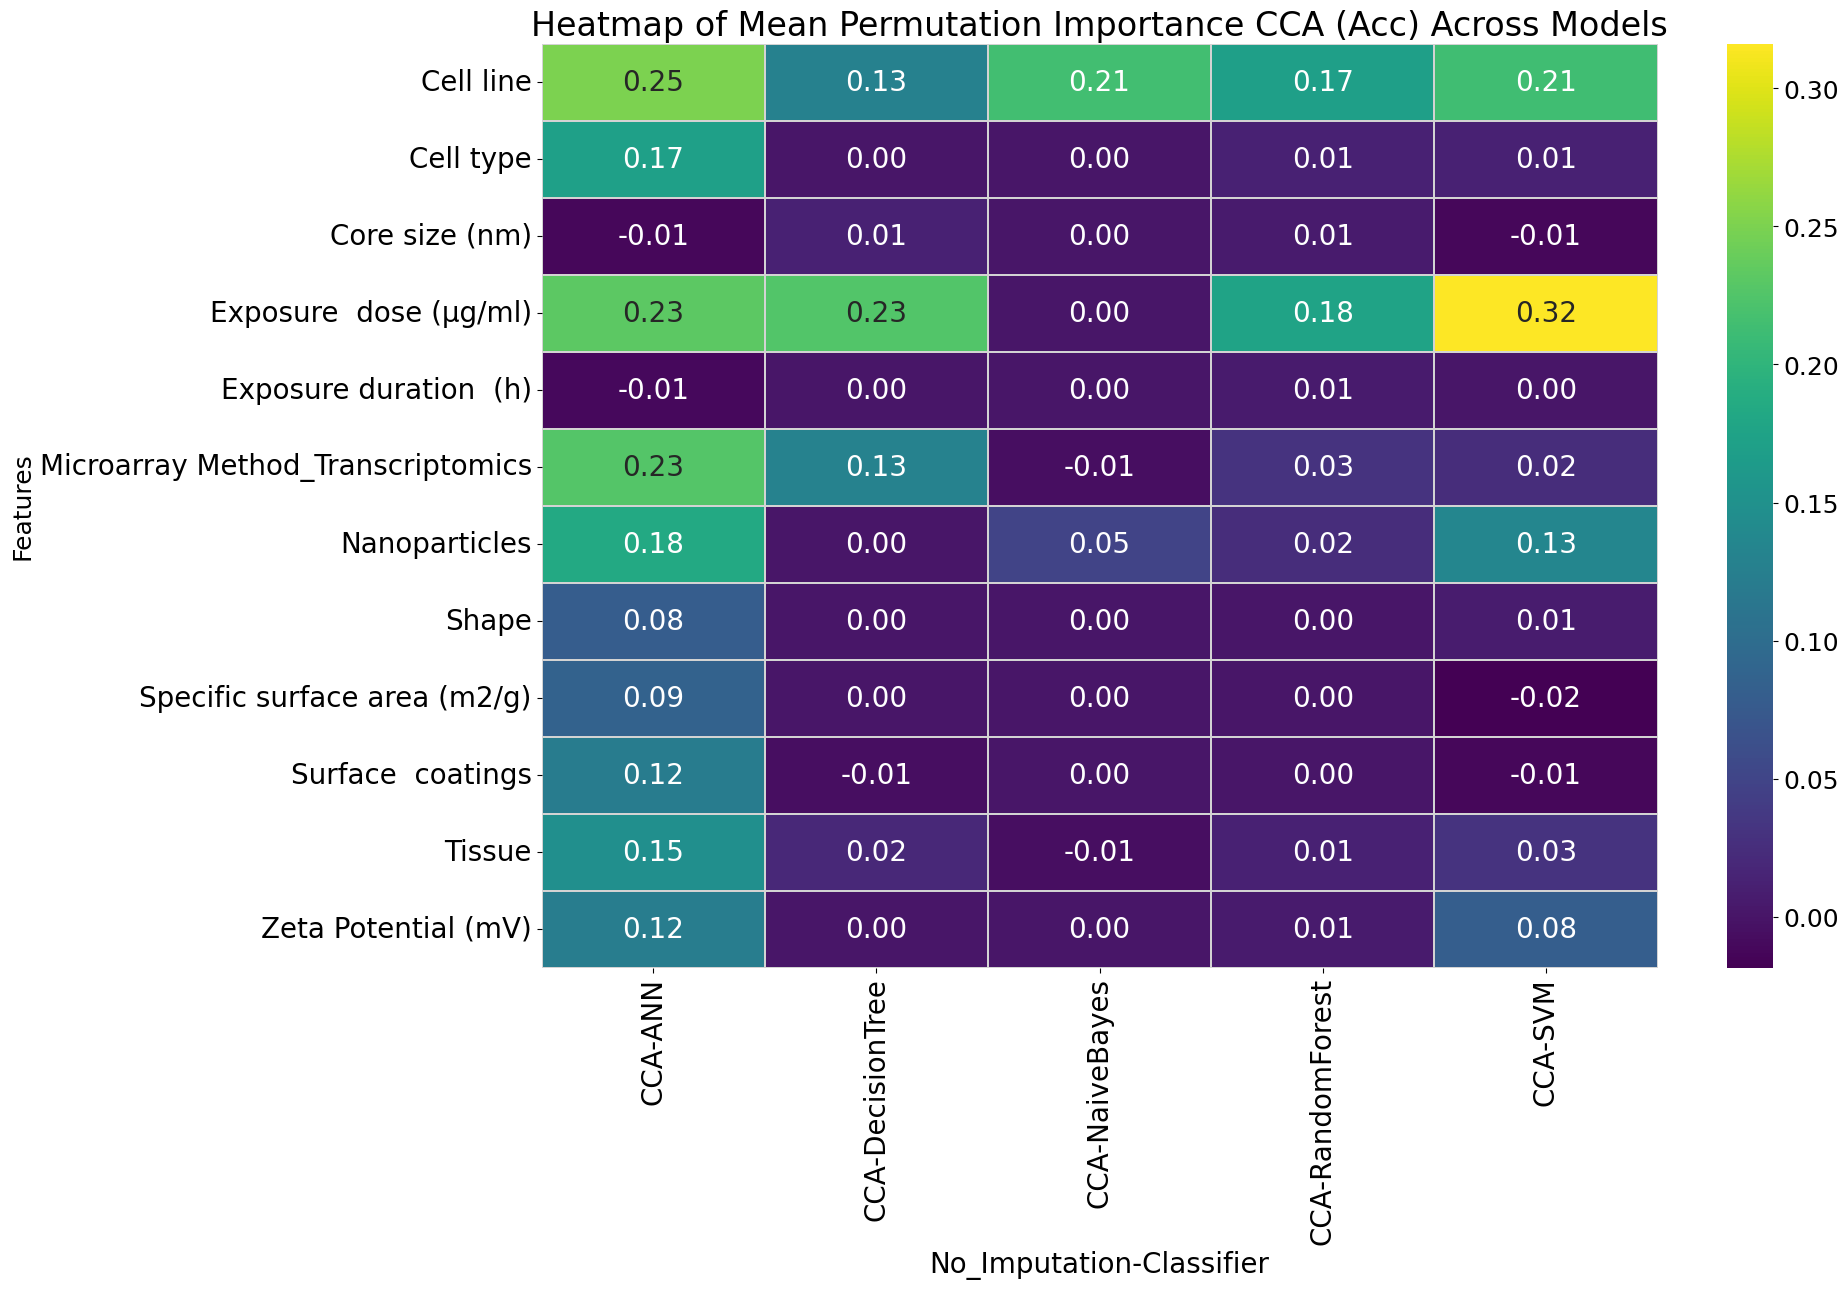

In [232]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Filter aggregated_pfi_ncv for 'accuracy' metric
df_permutation_importances_acc = aggregated_pfi_ncv[
    aggregated_pfi_ncv['Scoring_Metric'] == 'accuracy'
].copy()

# Add the 'Imputation' column, assuming "CCA" from context
df_permutation_importances_acc['Imputation'] = 'CCA'

# Rename 'mean' to 'Mean_Importance_Acc'
df_permutation_importances_acc.rename(columns={'mean': 'Mean_Importance_Acc'}, inplace=True)

# Create a copy for plotting (which is df_permutation_importances_acc_plot)
df_permutation_importances_acc_plot = df_permutation_importances_acc.copy()

# Replace the feature name for correct display in the pivot table
df_permutation_importances_acc_plot['Feature'] = df_permutation_importances_acc_plot['Feature'].replace('Specific surface area (m2/g) ', 'Specific surface area (m$^2$/g)')

# Pivot the DataFrame to prepare for heatmap
pivot_table_acc = df_permutation_importances_acc_plot.pivot_table(
    index="Feature",
    columns=["Imputation", "Classifier"],
    values="Mean_Importance_Acc"
)

plt.figure(figsize=(18, 12))
ax = sns.heatmap(
    pivot_table_acc,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    linewidths=.3,
    linecolor='lightgray',
    annot_kws={"fontsize": 20}
)
plt.title("Heatmap of Mean Permutation Importance CCA (Acc) Across Models", fontsize=24)
plt.ylabel("Features", fontsize=18)
plt.xlabel("No_Imputation-Classifier", fontsize=20)
plt.tick_params(axis='x', labelsize=20, rotation=90)
plt.tick_params(axis='y', labelsize=20)
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=18)
plt.show()